In [14]:
import numpy as np
import os

snapshots = [99, 50, 33, 25]

fields = [
    "SubhaloMassType",
    "SubhaloSFR",
    "SubhaloGasMetallicitySfrWeighted"
]

for snap in snapshots:

    filename = f"TNG_groupcat_data/snapshot_{snap}.npz"

    print("\n" + "=" * 60)
    print(f"SNAPSHOT {snap}")
    print("=" * 60)

    if not os.path.exists(filename):
        print("Fajl ne postoji!")
        continue

    data = np.load(filename)

# opseg masa---------------------------------------------------------
    stellar_mass = data["SubhaloMassType"][:, 4]
    
    h = 0.6774
    stellar_mass_msun = stellar_mass * 1e10 / h

    valid_mass = stellar_mass_msun[np.isfinite(stellar_mass_msun)]

    print("\nOPSEG ZVEZDANIH MASA:")
    print(f"Minimalna masa: {np.min(valid_mass):.4e} Msun")
    print(f"Maksimalna masa: {np.max(valid_mass):.4e} Msun")
#-------------------------------------------------------------------   

    # Broj ID-jeva
    ids = data["SubhaloID"]

    print(f"\nBroj subhaloa (ID): {len(ids)}")

    # Provera svakog polja
    lengths = []

    for field in fields:

        array = data[field]

        lengths.append(len(array))

        print(f"{field}:")
        print(f"    Oblik: {array.shape}")
        print(f"    Broj redova: {len(array)}")

    # Provera jednakog broja redova
    if len(set(lengths + [len(ids)])) == 1:

        print("\nSVI NIZOVI IMAJU ISTI BROJ REDOVA.")

    else:

        print("\nGRESKA: BROJ REDOVA SE NE POKLAPA")

    # Provera ID-jeva
    expected_ids = np.arange(len(ids))

    if np.array_equal(ids, expected_ids):

        print("ID-jevi odgovaraju indeksima u katalogu.")

    else:

        print("GRESKA: ID-jevi nisu pravilno poređani")

    # Provera da li postoje duplikati
    if len(np.unique(ids)) == len(ids):

        print("Nema dupliranih ID-jeva.")

    else:

        print("GRESKA: Postoje duplirani ID-jevi.")

    # Provera nedostajućih vrednosti
    for field in fields:

        array = data[field]

        print(
            f"{field} | NaN vrednosti:",
            np.isnan(array).sum()
        )

print("\nKraj")


SNAPSHOT 99

OPSEG ZVEZDANIH MASA:
Minimalna masa: 0.0000e+00 Msun
Maksimalna masa: 3.7056e+12 Msun

Broj subhaloa (ID): 4371211
SubhaloMassType:
    Oblik: (4371211, 6)
    Broj redova: 4371211
SubhaloSFR:
    Oblik: (4371211,)
    Broj redova: 4371211
SubhaloGasMetallicitySfrWeighted:
    Oblik: (4371211,)
    Broj redova: 4371211

SVI NIZOVI IMAJU ISTI BROJ REDOVA.
ID-jevi odgovaraju indeksima u katalogu.
Nema dupliranih ID-jeva.
SubhaloMassType | NaN vrednosti: 0
SubhaloSFR | NaN vrednosti: 0
SubhaloGasMetallicitySfrWeighted | NaN vrednosti: 0

SNAPSHOT 50

OPSEG ZVEZDANIH MASA:
Minimalna masa: 0.0000e+00 Msun
Maksimalna masa: 1.2894e+12 Msun

Broj subhaloa (ID): 5127294
SubhaloMassType:
    Oblik: (5127294, 6)
    Broj redova: 5127294
SubhaloSFR:
    Oblik: (5127294,)
    Broj redova: 5127294
SubhaloGasMetallicitySfrWeighted:
    Oblik: (5127294,)
    Broj redova: 5127294

SVI NIZOVI IMAJU ISTI BROJ REDOVA.
ID-jevi odgovaraju indeksima u katalogu.
Nema dupliranih ID-jeva.
Subhalo

# Filtriranje: pozitivna zvezdana masa

In [15]:
import numpy as np

snapshots = [99, 50, 33, 25]

all_data = {}

for snap in snapshots:

    filename = f"TNG_groupcat_data/snapshot_{snap}.npz"

    loaded = np.load(filename)

    all_data[snap] = {
        key: loaded[key]
        for key in loaded.files
    }

    loaded.close()

    print(f'Snapshot {snap}: učitan')

Snapshot 99: učitan
Snapshot 50: učitan
Snapshot 33: učitan
Snapshot 25: učitan


In [16]:
snapshots = [99, 50, 33, 25]

filtered_data = {}

for snap in snapshots:

    print("\n" + "=" * 50)
    print(f"SNAPSHOT {snap}")
    print("=" * 50)

    data = all_data[snap]

    # Ukupan broj objekata pre filtriranja
    N_before = len(data["SubhaloID"])

    # Zvezdana masa (indeks 4)
    stellar_mass = data["SubhaloMassType"][:, 4]

    # Selekcija objekata sa pozitivnom zvezdanom masom
    mask = stellar_mass > 0

    # Broj objekata nakon filtriranja
    N_after = np.sum(mask)

    # Broj izbačenih objekata
    N_removed = N_before - N_after

    # Filtriranje svih polja istom maskom
    filtered_data[snap] = {
        field: data[field][mask]
        for field in [
            "SubhaloID",
            "SubhaloMassType",
            "SubhaloSFR",
            "SubhaloGasMetallicitySfrWeighted"
        ]
    }

    print("Broj objekata pre filtriranja:", N_before)
    print("Broj objekata nakon filtriranja:", N_after)
    print("Broj izbačenih objekata:", N_removed)

    print(
        "Procenat izbačenih objekata:",
        round(100 * N_removed / N_before, 2), "%"
    )

print("\nKraj")



SNAPSHOT 99
Broj objekata pre filtriranja: 4371211
Broj objekata nakon filtriranja: 337261
Broj izbačenih objekata: 4033950
Procenat izbačenih objekata: 92.28 %

SNAPSHOT 50
Broj objekata pre filtriranja: 5127294
Broj objekata nakon filtriranja: 492655
Broj izbačenih objekata: 4634639
Procenat izbačenih objekata: 90.39 %

SNAPSHOT 33
Broj objekata pre filtriranja: 5621338
Broj objekata nakon filtriranja: 680244
Broj izbačenih objekata: 4941094
Procenat izbačenih objekata: 87.9 %

SNAPSHOT 25
Broj objekata pre filtriranja: 5828784
Broj objekata nakon filtriranja: 836537
Broj izbačenih objekata: 4992247
Procenat izbačenih objekata: 85.65 %

Kraj


# Filtriranje: logSFR>-4

In [17]:
import numpy as np

final_data = {}

for snap in snapshots:

    data = filtered_data[snap]

    # Racunanje logSFR
    logSFR = np.full(len(data["SubhaloSFR"]), -np.inf)

    positive_sfr = data["SubhaloSFR"] > 0
    logSFR[positive_sfr] = np.log10(data["SubhaloSFR"][positive_sfr])

    # Uslov: logSFR > -4
    mask = logSFR > -4

    # Primena maske na sva polja
    final_data[snap] = {
        key: data[key][mask]
        for key in data.keys()
    }

    N_before = len(data["SubhaloID"])
    N_after = np.sum(mask)
    N_removed = N_before - N_after

    print("=" * 50)
    print(f"SNAPSHOT {snap}")
    print("=" * 50)
    print(f"Broj objekata pre dodatnog filtriranja: {N_before}")
    print(f"Broj objekata nakon dodatnog filtriranja: {N_after}")
    print(f"Broj izbacenih objekata: {N_removed}")
    print(f"Procenat izbacenih objekata: {100*N_removed/N_before:.2f} %")

SNAPSHOT 99
Broj objekata pre dodatnog filtriranja: 337261
Broj objekata nakon dodatnog filtriranja: 71575
Broj izbacenih objekata: 265686
Procenat izbacenih objekata: 78.78 %
SNAPSHOT 50
Broj objekata pre dodatnog filtriranja: 492655
Broj objekata nakon dodatnog filtriranja: 147241
Broj izbacenih objekata: 345414
Procenat izbacenih objekata: 70.11 %
SNAPSHOT 33
Broj objekata pre dodatnog filtriranja: 680244
Broj objekata nakon dodatnog filtriranja: 274398
Broj izbacenih objekata: 405846
Procenat izbacenih objekata: 59.66 %
SNAPSHOT 25
Broj objekata pre dodatnog filtriranja: 836537
Broj objekata nakon dodatnog filtriranja: 425208
Broj izbacenih objekata: 411329
Procenat izbacenih objekata: 49.17 %


# SFMS i MW-like

In [18]:
import numpy as np
import pandas as pd
from sklearn.linear_model import HuberRegressor


protoMWmass = [
    10.68,
    10.48,
    10.28,
    9.98
]


# Veza između snapshot-a i crvenog pomaka
snapshot_redshifts = {
    99: 0,
    50: 1,
    33: 2,
    25: 3
}


# Rezultati
TNG_populations = {}
MW_statistics = {}
MW_population = {}


for snap, z in snapshot_redshifts.items():

    data = final_data[snap]

    # Izdvajanje zvezdane mase, SFR-a i metaliciteta
    stellar_mass = data["SubhaloMassType"][:, 4]
    sfr = data["SubhaloSFR"]
    Z_weighted = data["SubhaloGasMetallicitySfrWeighted"]

    # Identifikatori galaksija
    ids = data["SubhaloID"]

    # Konverzija mase u Msun
    mass_msun = stellar_mass * 1e10 / 0.6774

    # Logaritamske vrednosti
    logM = np.log10(mass_msun)
    logSFR = np.log10(sfr)

    # SFMS fit pomoću Huber regresije
    X = logM.reshape(-1, 1)
    y = logSFR

    huber = HuberRegressor()
    huber.fit(X, y)

    # Odstupanje od SFMS relacije
    logSFR_fit = huber.predict(X)
    delta_logSFR = logSFR - logSFR_fit

    # Podela na upper i lower populaciju
    upper_mask = delta_logSFR > -1
    lower_mask = delta_logSFR <= -1

    upper = pd.DataFrame({
        "id": ids[upper_mask],
        "logM": logM[upper_mask],
        "logSFR": logSFR[upper_mask],
        "Z_weighted": Z_weighted[upper_mask],
        "delta_logSFR": delta_logSFR[upper_mask]
    })

    lower = pd.DataFrame({
        "id": ids[lower_mask],
        "logM": logM[lower_mask],
        "logSFR": logSFR[lower_mask],
        "Z_weighted": Z_weighted[lower_mask],
        "delta_logSFR": delta_logSFR[lower_mask]
    })

    # Izdvajanje MW-like populacije iz upper populacije
    MW_mass = protoMWmass[z]

    MW_mask = np.abs(upper["logM"] - MW_mass) <= 0.2
    MW_like = upper[MW_mask].copy()

    # Čuvanje MW-like populacije za CSV kataloge
    MW_population[z] = MW_like.copy()

    # Čuvanje rezultata
    TNG_populations[z] = {
        "all": pd.DataFrame({
            "id": ids,
            "logM": logM,
            "logSFR": logSFR,
            "Z_weighted": Z_weighted,
            "delta_logSFR": delta_logSFR
        }),
        "upper": upper,
        "lower": lower,
        "mw_mass_like": MW_like,
        "huber": huber
    }

    # Osnovna statistika MW-like populacije
    MW_statistics[z] = {
        "N": len(MW_like),
        "median_logM": MW_like["logM"].median(),
        "median_logSFR": MW_like["logSFR"].median()
    }

    print("=" * 50)
    print(f"SNAPSHOT {snap} | z = {z}")
    print("=" * 50)
    print(f"Ukupan broj galaksija: {len(ids)}")
    print(f"Upper populacija: {len(upper)}")
    print(f"Lower populacija: {len(lower)}")
    print(f"MW-like populacija: {len(MW_like)}")
    print(f"SFMS nagib: {huber.coef_[0]:.4f}")
    print(f"SFMS odsečak: {huber.intercept_:.4f}")

SNAPSHOT 99 | z = 0
Ukupan broj galaksija: 71575
Upper populacija: 68438
Lower populacija: 3137
MW-like populacija: 836
SFMS nagib: 0.8840
SFMS odsečak: -8.9508
SNAPSHOT 50 | z = 1
Ukupan broj galaksija: 147241
Upper populacija: 143950
Lower populacija: 3291
MW-like populacija: 1631
SFMS nagib: 0.9980
SFMS odsečak: -9.5499
SNAPSHOT 33 | z = 2
Ukupan broj galaksija: 274398
Upper populacija: 269569
Lower populacija: 4829
MW-like populacija: 1459
SFMS nagib: 1.0448
SFMS odsečak: -9.5911
SNAPSHOT 25 | z = 3
Ukupan broj galaksija: 425208
Upper populacija: 418428
Lower populacija: 6780
MW-like populacija: 1112
SFMS nagib: 1.0742
SFMS odsečak: -9.5490


In [19]:
print(MW_population[0].columns.tolist())
for z in range(4):

    df_output = MW_population[z].copy()

    filename = f"MW_population_z{z}weighted.csv"

    df_output.to_csv(filename, index=False)

    print(f"z={z}: sačuvano {len(df_output)} objekata")

['id', 'logM', 'logSFR', 'Z_weighted', 'delta_logSFR']
z=0: sačuvano 836 objekata
z=1: sačuvano 1631 objekata
z=2: sačuvano 1459 objekata
z=3: sačuvano 1112 objekata


# SFMS fit u ograničenom masenom opsegu (9 < logM < 11.2)

In [20]:
"""
import numpy as np
import pandas as pd
from sklearn.linear_model import HuberRegressor


protoMWmass = [
    10.68,
    10.48,
    10.28,
    9.98
]


# Veza između snapshot-a i crvenog pomaka
snapshot_redshifts = {
    99: 0,
    50: 1,
    33: 2,
    25: 3
}

# Rezultati
TNG_populations = {}
MW_statistics = {}

for snap, z in snapshot_redshifts.items():

    data = final_data[snap]

    # Izvlacenje zvezdane mase i SFR-a
    stellar_mass = data["SubhaloMassType"][:, 4]
    sfr = data["SubhaloSFR"]

    # Konverzija mase u Msun
    mass_msun = stellar_mass * 1e10 / 0.6774

    # Logaritamske vrednosti
    logM = np.log10(mass_msun)
    logSFR = np.log10(sfr)
#======================================================================================================================
    


    # SFMS fit samo u ogranicenom masenom opsegu
    fit_mask = (logM > 9) & (logM < 11.2)

    X = logM[fit_mask].reshape(-1, 1)
    y = logSFR[fit_mask]

    huber = HuberRegressor()
    huber.fit(X, y)

    # Predikcija SFMS relacije za sve galaksije
    logSFR_fit = huber.predict(logM.reshape(-1, 1))

    # Odstupanje od SFMS relacije
    delta_logSFR = logSFR - logSFR_fit





    #=================================================================================================================

    # Podela na upper i lower populaciju
    upper_mask = delta_logSFR > -1
    lower_mask = delta_logSFR <= -1

    upper = pd.DataFrame({
        "id": data["SubhaloID"][upper_mask],
        "logM": logM[upper_mask],
        "logSFR": logSFR[upper_mask],
        "delta_logSFR": delta_logSFR[upper_mask]
    })

    lower = pd.DataFrame({
        "id": data["SubhaloID"][lower_mask],
        "logM": logM[lower_mask],
        "logSFR": logSFR[lower_mask],
        "delta_logSFR": delta_logSFR[lower_mask]
    })

    # Izdvajanje MW-like populacije iz upper populacije
    MW_mass = protoMWmass[z]

    MW_mask = np.abs(upper["logM"] - MW_mass) <= 0.2
    MW_like = upper[MW_mask].copy()

    # Cuvanje rezultata
    TNG_populations[z] = {
        "all": pd.DataFrame({
            "id": data["SubhaloID"],
            "logM": logM,
            "logSFR": logSFR,
            "delta_logSFR": delta_logSFR
        }),
        "upper": upper,
        "lower": lower,
        "mw_mass_like": MW_like,
        "huber": huber
    }

    # Osnovna statistika MW-like populacije
    MW_statistics[z] = {
        "N": len(MW_like),
        "median_logM": MW_like["logM"].median(),
        "median_logSFR": MW_like["logSFR"].median()
    }

    print("=" * 50)
    print(f"SNAPSHOT {snap} | z = {z}")
    print("=" * 50)
    print(f"Ukupan broj galaksija: {len(data['SubhaloID'])}")
    print(f"Upper populacija: {len(upper)}")
    print(f"Lower populacija: {len(lower)}")
    print(f"MW-like populacija: {len(MW_like)}")
    print(f"SFMS nagib: {huber.coef_[0]:.4f}")
    print(f"SFMS odsečak: {huber.intercept_:.4f}")
#===================================================================================================
    print(f"Galaksije korišćene za SFMS fit: {len(X)}")
"""

'\nimport numpy as np\nimport pandas as pd\nfrom sklearn.linear_model import HuberRegressor\n\n\nprotoMWmass = [\n    10.68,\n    10.48,\n    10.28,\n    9.98\n]\n\n\n# Veza između snapshot-a i crvenog pomaka\nsnapshot_redshifts = {\n    99: 0,\n    50: 1,\n    33: 2,\n    25: 3\n}\n\n# Rezultati\nTNG_populations = {}\nMW_statistics = {}\n\nfor snap, z in snapshot_redshifts.items():\n\n    data = final_data[snap]\n\n    # Izvlacenje zvezdane mase i SFR-a\n    stellar_mass = data["SubhaloMassType"][:, 4]\n    sfr = data["SubhaloSFR"]\n\n    # Konverzija mase u Msun\n    mass_msun = stellar_mass * 1e10 / 0.6774\n\n    # Logaritamske vrednosti\n    logM = np.log10(mass_msun)\n    logSFR = np.log10(sfr)\n#======================================================================================================================\n\n\n\n    # SFMS fit samo u ogranicenom masenom opsegu\n    fit_mask = (logM > 9) & (logM < 11.2)\n\n    X = logM[fit_mask].reshape(-1, 1)\n    y = logSFR[fit_mask]\n\n 

# 2. SFMS

In [21]:
'''
TNG_upper_fit = {}

for snap, z in snapshot_redshifts.items():

    upper = TNG_populations[z]["upper"]

    
    X = upper["logM"].values.reshape(-1, 1)
    y = upper["logSFR"].values

    
    huber_upper = HuberRegressor()
    huber_upper.fit(X, y)

    
    logSFR_fit = huber_upper.predict(X)

    
    delta_logSFR = y - logSFR_fit

    
    upper_mask_new = delta_logSFR > -1
    lower_mask_new = delta_logSFR <= -1

    upper_new = pd.DataFrame({
        "id": upper["id"].values[upper_mask_new],
        "logM": upper["logM"].values[upper_mask_new],
        "logSFR": upper["logSFR"].values[upper_mask_new],
        "delta_logSFR": delta_logSFR[upper_mask_new]
    })

    lower_new = pd.DataFrame({
        "id": upper["id"].values[lower_mask_new],
        "logM": upper["logM"].values[lower_mask_new],
        "logSFR": upper["logSFR"].values[lower_mask_new],
        "delta_logSFR": delta_logSFR[lower_mask_new]
    })

    
    TNG_upper_fit[z] = {
        "all": upper.copy(),
        "upper": upper_new,
        "lower": lower_new,
        "huber": huber_upper
    }

    print("=" * 50)
    print(f"SNAPSHOT {snap} | z = {z}")
    print("=" * 50)
    print(f"Broj galaksija u novom SFMS fit-u: {len(upper)}")
    print(f"Nova upper populacija: {len(upper_new)}")
    print(f"Nova lower populacija: {len(lower_new)}")
    print(f"SFMS nagib: {huber_upper.coef_[0]:.4f}")
    print(f"SFMS odsečak: {huber_upper.intercept_:.4f}")
'''

'\nTNG_upper_fit = {}\n\nfor snap, z in snapshot_redshifts.items():\n\n    upper = TNG_populations[z]["upper"]\n\n\n    X = upper["logM"].values.reshape(-1, 1)\n    y = upper["logSFR"].values\n\n\n    huber_upper = HuberRegressor()\n    huber_upper.fit(X, y)\n\n\n    logSFR_fit = huber_upper.predict(X)\n\n\n    delta_logSFR = y - logSFR_fit\n\n\n    upper_mask_new = delta_logSFR > -1\n    lower_mask_new = delta_logSFR <= -1\n\n    upper_new = pd.DataFrame({\n        "id": upper["id"].values[upper_mask_new],\n        "logM": upper["logM"].values[upper_mask_new],\n        "logSFR": upper["logSFR"].values[upper_mask_new],\n        "delta_logSFR": delta_logSFR[upper_mask_new]\n    })\n\n    lower_new = pd.DataFrame({\n        "id": upper["id"].values[lower_mask_new],\n        "logM": upper["logM"].values[lower_mask_new],\n        "logSFR": upper["logSFR"].values[lower_mask_new],\n        "delta_logSFR": delta_logSFR[lower_mask_new]\n    })\n\n\n    TNG_upper_fit[z] = {\n        "all": uppe

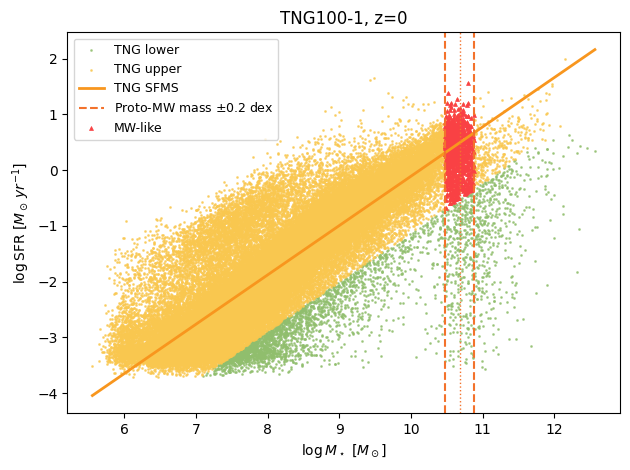

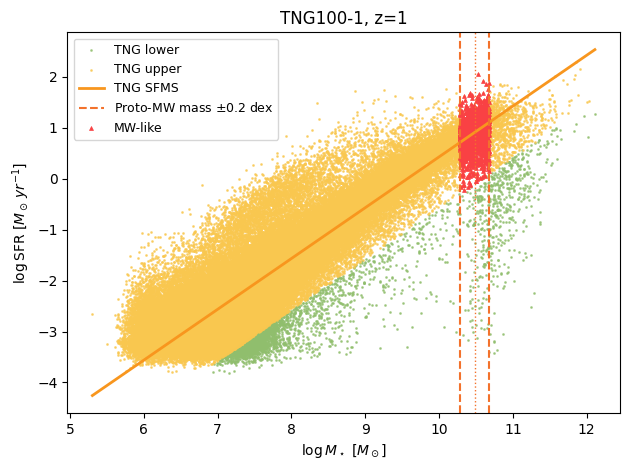

C:\Users\Lenovo\AppData\Local\Temp\ipykernel_16336\1689410732.py:93: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  plt.tight_layout()


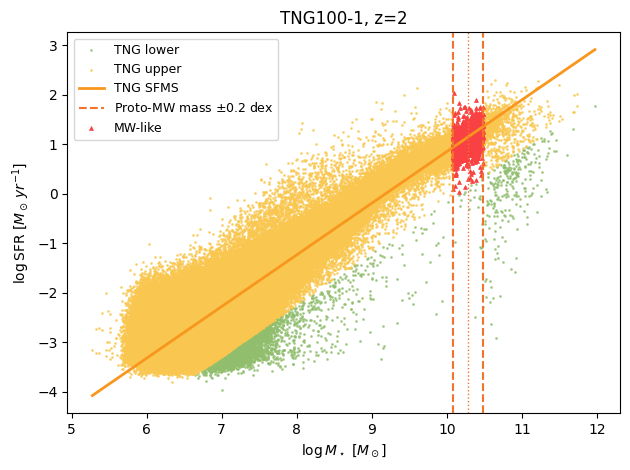

C:\Users\Lenovo\AppData\Local\Temp\ipykernel_16336\1689410732.py:93: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  plt.tight_layout()


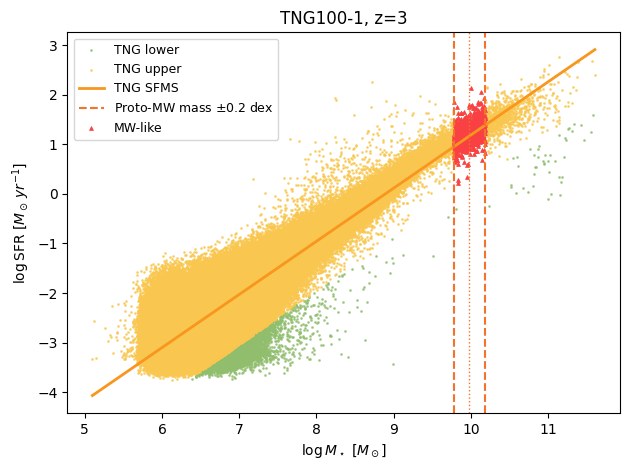

In [22]:
import matplotlib.pyplot as plt

for z in snapshot_redshifts.values():

    upper = TNG_populations[z]["upper"]
    lower = TNG_populations[z]["lower"]
    mw_mass_like = TNG_populations[z]["mw_mass_like"]
    tng_huber = TNG_populations[z]["huber"]
    df_sfms = TNG_populations[z]["all"]

    plt.figure()

    # TNG lower
    plt.scatter(
        lower["logM"],
        lower["logSFR"],
        s=1,
        alpha=0.7,
        color="#90be6d",
        label="TNG lower"
    )

    # TNG upper
    plt.scatter(
        upper["logM"],
        upper["logSFR"],
        s=1,
        alpha=0.7,
        color="#f9c74f",
        label="TNG upper"
    )

    # TNG SFMS
    x_tng = np.linspace(
        df_sfms["logM"].min(),
        df_sfms["logM"].max(),
        200
    )

    y_tng = tng_huber.predict(
        x_tng.reshape(-1, 1)
    )

    plt.plot(
        x_tng,
        y_tng,
        color="#f8961e",
        linestyle="-",
        linewidth=2,
        label="TNG SFMS"
    )

    # MW maseni opseg
    plt.axvline(
        protoMWmass[z] - 0.2,
        color="#f3722c",
        linestyle="--",
        linewidth=1.5
    )

    plt.axvline(
        protoMWmass[z] + 0.2,
        color="#f3722c",
        linestyle="--",
        linewidth=1.5,
        label=r"Proto-MW mass $\pm0.2$ dex"
    )

    # Proto-MW masa
    plt.axvline(
        protoMWmass[z],
        color="#f3722c",
        linestyle=":",
        linewidth=1
    )

    # MW-like galaksije
    plt.scatter(
        mw_mass_like["logM"],
        mw_mass_like["logSFR"],
        marker="^",
        s=8,
        color="#f94144",
        linewidth=0.5,
        label="MW-like"
    )

    plt.xlabel(r"$\log M_\star\ [M_\odot]$")
    plt.ylabel(r"$\log \mathrm{SFR}\ [M_\odot\,yr^{-1}]$")
    plt.title(f"TNG100-1, z={z}")

    plt.legend(fontsize=9)
    plt.tight_layout()
    plt.show()

In [23]:
for z in snapshot_redshifts.values():

    mw_mass_like = TNG_populations[z]["mw_mass_like"]

    median_logSFR = mw_mass_like["logSFR"].median()

    p16 = np.percentile(mw_mass_like["logSFR"], 16)
    p84 = np.percentile(mw_mass_like["logSFR"], 84)

    print(
        f"z = {z}: "
        f"median logSFR = {median_logSFR:.4f}, "
        f"16–84% interval = [{p16:.4f}, {p84:.4f}]"
    )   

z = 0: median logSFR = 0.3531, 16–84% interval = [-0.1525, 0.7263]
z = 1: median logSFR = 0.9290, 16–84% interval = [0.6264, 1.1707]
z = 2: median logSFR = 1.1131, 16–84% interval = [0.8823, 1.3372]
z = 3: median logSFR = 1.2287, 16–84% interval = [1.0597, 1.4121]


# \Delta\log\mathrm{SFR} histogram

C:\Users\Lenovo\AppData\Local\Temp\ipykernel_16336\4002987399.py:19: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


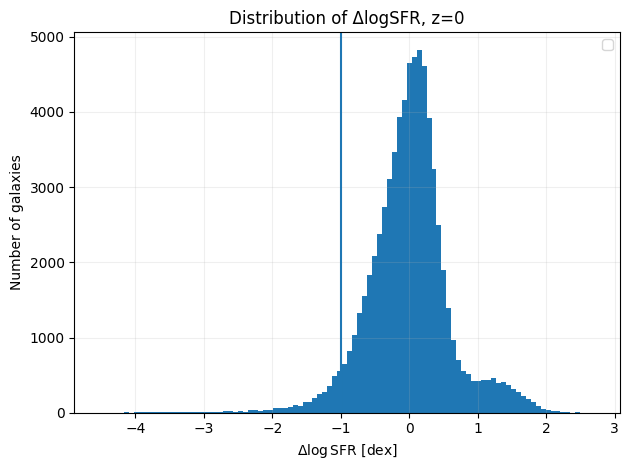

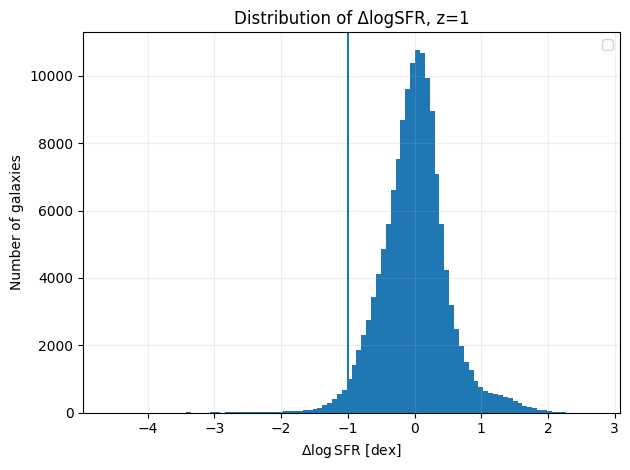

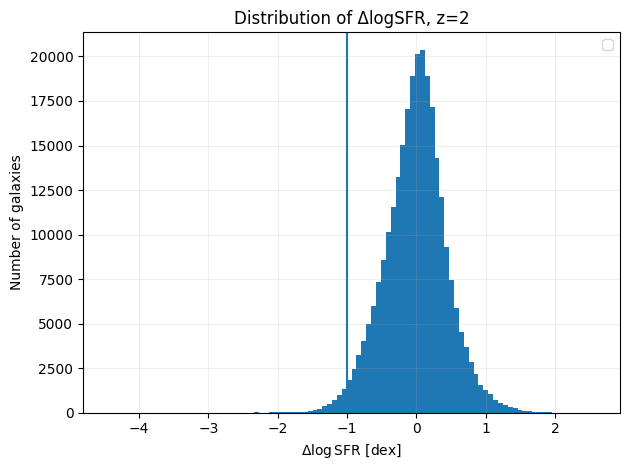

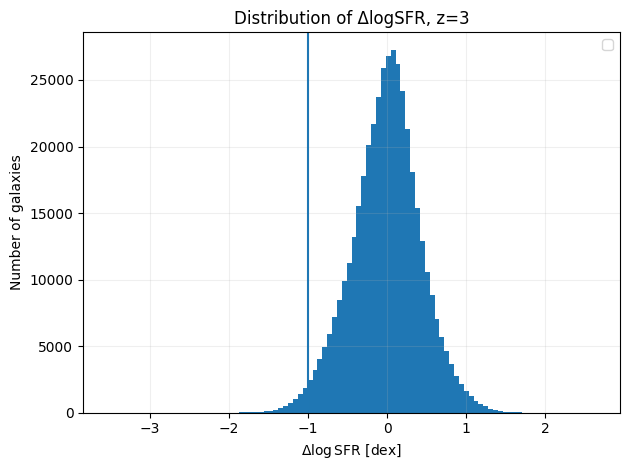

In [24]:
for z in snapshot_redshifts.values():

    df = TNG_populations[z]["all"]

    delta_logSFR = df["delta_logSFR"]

    plt.figure()

    plt.hist(delta_logSFR, bins=100)

    
    plt.axvline(-1)

    plt.xlabel(r"$\Delta \log \mathrm{SFR}$ [dex]")
    plt.ylabel("Number of galaxies")

    plt.title(f"Distribution of ΔlogSFR, z={z}")

    plt.legend()
    plt.grid(alpha=0.2)

    plt.tight_layout()
    plt.show()


# COSMOS I TNG GRAFICI

ucitavanje cosmos podataka
Broj COSMOS objekata nakon filtriranja: 493803
COSMOS SFMS fit z=0: slope = 0.5981, intercept = -5.9867
COSMOS SFMS fit z=1: slope = 0.6114, intercept = -5.4902
COSMOS SFMS fit z=2: slope = 0.6586, intercept = -5.4334
COSMOS SFMS fit z=3: slope = 0.6003, intercept = -4.7102

COSMOS | z ≈ 0
Ukupan broj COSMOS galaksija: 78740
Upper populacija: 69049
Lower populacija: 9691
--------------------------------------------------
MW-like populacija: N = 610
Median logSFR = 0.2800
16–84% interval = [-0.3000, 0.7800]
--------------------------------------------------
SFMS nagib: 0.5981
SFMS odsečak: -5.9867


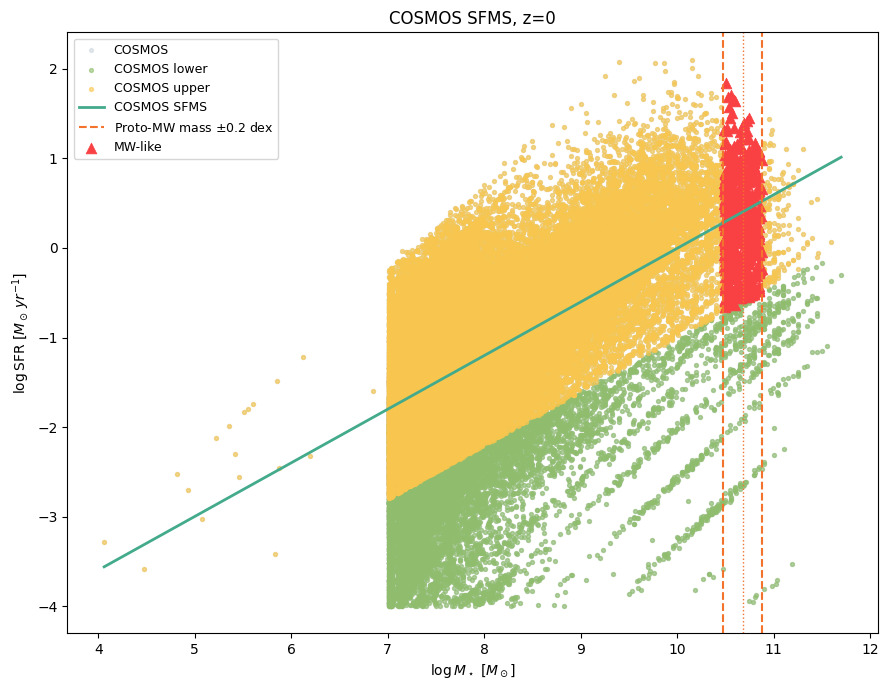


COSMOS | z ≈ 1
Ukupan broj COSMOS galaksija: 125257
Upper populacija: 111214
Lower populacija: 14043
--------------------------------------------------
MW-like populacija: N = 3373
Median logSFR = 1.2100
16–84% interval = [0.3300, 1.6300]
--------------------------------------------------
SFMS nagib: 0.6114
SFMS odsečak: -5.4902


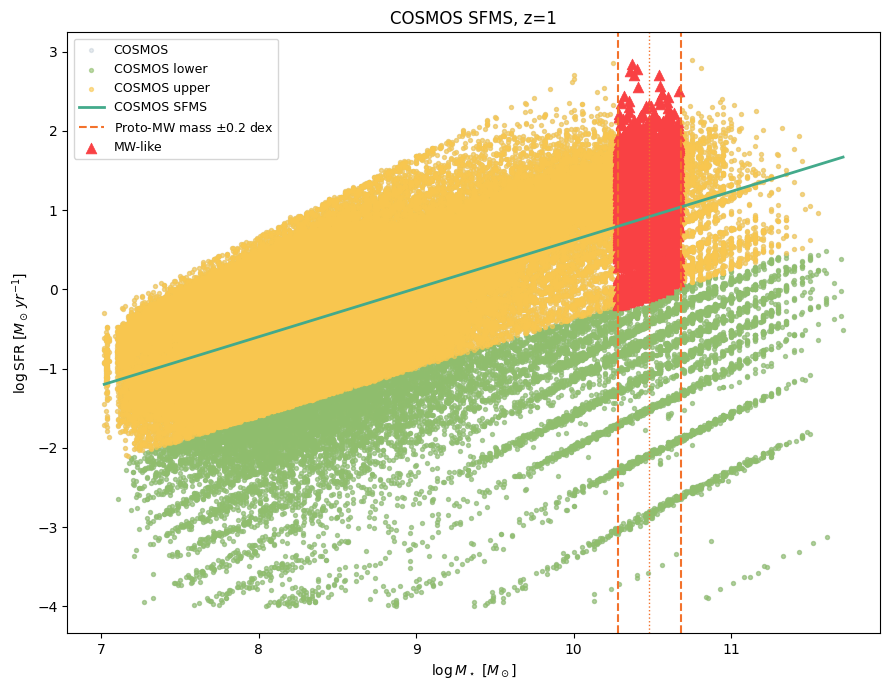


COSMOS | z ≈ 2
Ukupan broj COSMOS galaksija: 166470
Upper populacija: 153818
Lower populacija: 12652
--------------------------------------------------
MW-like populacija: N = 10103
Median logSFR = 1.5100
16–84% interval = [1.1100, 1.9400]
--------------------------------------------------
SFMS nagib: 0.6586
SFMS odsečak: -5.4334


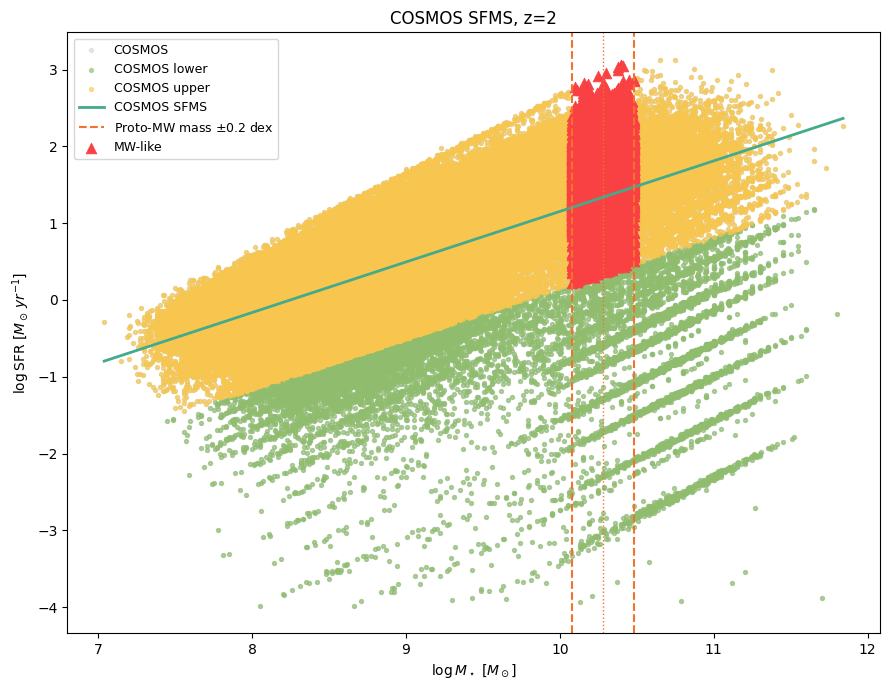


COSMOS | z ≈ 3
Ukupan broj COSMOS galaksija: 123336
Upper populacija: 118493
Lower populacija: 4843
--------------------------------------------------
MW-like populacija: N = 15482
Median logSFR = 1.3700
16–84% interval = [0.8800, 1.8300]
--------------------------------------------------
SFMS nagib: 0.6003
SFMS odsečak: -4.7102


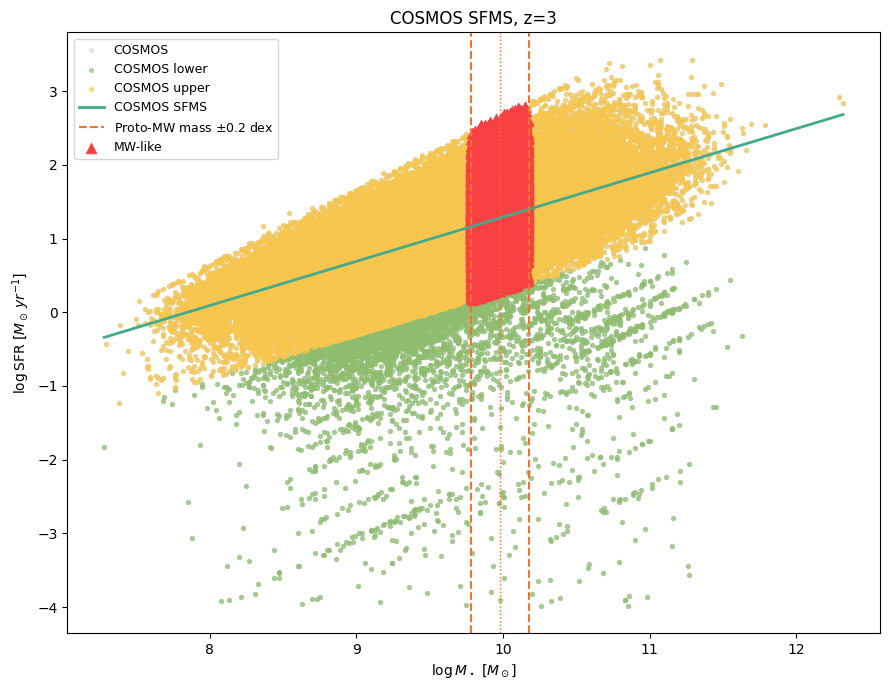

In [25]:
import requests
import pandas as pd
import numpy as np
from sklearn.linear_model import HuberRegressor
import matplotlib.pyplot as plt
from astropy.table import Table
import os
import time

COSMOS_FILE = "asu.fit"

protoMWmass = [
    10.68,
    10.48,
    10.28,
    9.98
]

print("ucitavanje cosmos podataka")

cos = Table.read(
    COSMOS_FILE,
    format="fits"
).to_pandas()


#cosmos filteri

cos = cos[
    (cos["zphot"] > 0) &
    (cos["zphot"] < 4) &
    (cos["MassMed"] > 0) &
    (cos["SFR"] > -5)
].copy()


#cosmos velicine

cos["logM"] = cos["MassMed"]
cos["logSFR"] = cos["SFR"]


#sfms filter

cos = cos[
    #cos["logSFR"] > -3.5
    cos["logSFR"] > -4
].copy()


print(
    f"Broj COSMOS objekata nakon filtriranja: {len(cos)}"
)

def get_cosmos_bin(z):

    if z == 0:

        return cos[
            (cos["zphot"] >= 0) &
            (cos["zphot"] < 0.5)
        ].copy()

    elif z == 1:

        return cos[
            (cos["zphot"] >= 0.5) &
            (cos["zphot"] < 1)
        ].copy()

    elif z == 2:

        return cos[
            (cos["zphot"] >= 1) &
            (cos["zphot"] < 2)
        ].copy()

    elif z == 3:

        return cos[
            (cos["zphot"] >= 2) &
            (cos["zphot"] < 4)
        ].copy()

cosmos_fits = {}


for z in range(4):

    cos_sub = get_cosmos_bin(z)

    if len(cos_sub) < 2:

        print(
            f"Premalo COSMOS objekata za z={z}"
        )

        continue


    X = (
        cos_sub["logM"]
        .values
        .reshape(-1, 1)
    )

    y = cos_sub["logSFR"].values


    huber = HuberRegressor()

    huber.fit(
        X,
        y
    )


    cosmos_fits[z] = huber


    print(
        f"COSMOS SFMS fit z={z}: "
        f"slope = {huber.coef_[0]:.4f}, "
        f"intercept = {huber.intercept_:.4f}"
    )

COSMOS_populations = {}
COSMOS_MW_statistics = {}


for z in cosmos_fits.keys():

    print()
    print("=" * 70)
    print(f"COSMOS | z ≈ {z}")
    print("=" * 70)


    cos_sub = get_cosmos_bin(z).copy()


    X = cos_sub["logM"].values.reshape(-1, 1)
    y = cos_sub["logSFR"].values

    cosmos_huber = HuberRegressor()
    cosmos_huber.fit(X, y)

    cos_sub["SFMS_fit"] = cosmos_huber.predict(X)


    cos_sub["delta_logSFR"] = (
        cos_sub["logSFR"] - cos_sub["SFMS_fit"]
    )


    upper = cos_sub[
        cos_sub["delta_logSFR"] > -1.0
    ].copy()

    lower = cos_sub[
        cos_sub["delta_logSFR"] <= -1.0
    ].copy()


    MW_mass = protoMWmass[z]

    mw_mass_like = upper[
        np.abs(
            upper["logM"] - MW_mass
        ) <= 0.2
    ].copy()


    N = len(mw_mass_like)



    mw_logSFR = mw_mass_like["logSFR"].values

    median_logSFR = np.median(mw_logSFR)

    p16 = np.percentile(mw_logSFR, 16)

    p84 = np.percentile(mw_logSFR, 84)


    

    COSMOS_populations[z] = {

        "all": cos_sub,

        "upper": upper,

        "lower": lower,

        "mw_mass_like": mw_mass_like,

        "huber": cosmos_huber
    }


    COSMOS_MW_statistics[z] = {

        "N": N,

        "median_logSFR": median_logSFR,

        "p16_logSFR": p16,

        "p84_logSFR": p84
    }
    
    
    
    print(f"Ukupan broj COSMOS galaksija: {len(cos_sub)}")

    print(f"Upper populacija: {len(upper)}")

    print(f"Lower populacija: {len(lower)}")

    print("-" * 50)

    print(f"MW-like populacija: N = {N}")

    print(f"Median logSFR = {median_logSFR:.4f}")

    print(f"16–84% interval = [{p16:.4f}, {p84:.4f}]")

    print("-" * 50)

    print(f"SFMS nagib: {cosmos_huber.coef_[0]:.4f}")

    print(f"SFMS odsečak: {cosmos_huber.intercept_:.4f}")


    plt.figure(figsize=(9, 7))


    plt.scatter(
        cos_sub["logM"],
        cos_sub["logSFR"],
        s=8,
        alpha=0.15,
        color="#577590",
        label="COSMOS"
    )


    plt.scatter(
        lower["logM"],
        lower["logSFR"],
        s=8,
        alpha=0.6,
        color="#90be6d",
        label="COSMOS lower"
    )


    plt.scatter(
        upper["logM"],
        upper["logSFR"],
        s=8,
        alpha=0.6,
        color="#f9c74f",
        label="COSMOS upper"
    )


    x_cos = np.linspace(
        cos_sub["logM"].min(),
        cos_sub["logM"].max(),
        200
    )

    y_cos = cosmos_huber.predict(
        x_cos.reshape(-1, 1)
    )

    plt.plot(
        x_cos,
        y_cos,
        color="#43aa8b",
        linewidth=2,
        label="COSMOS SFMS"
    )


    plt.axvline(
        MW_mass - 0.2,
        color="#f3722c",
        linestyle="--",
        linewidth=1.5
    )

    plt.axvline(
        MW_mass + 0.2,
        color="#f3722c",
        linestyle="--",
        linewidth=1.5,
        label=r"Proto-MW mass $\pm 0.2$ dex"
    )


    plt.axvline(
        MW_mass,
        color="#f3722c",
        linestyle=":",
        linewidth=1
    )


    plt.scatter(
        mw_mass_like["logM"],
        mw_mass_like["logSFR"],
        marker="^",
        s=60,
        color="#f94144",
        linewidth=0.5,
        label="MW-like"
    )


    plt.xlabel(r"$\log M_\star\ [M_\odot]$")

    plt.ylabel(r"$\log \mathrm{SFR}\ "r"[M_\odot\,yr^{-1}]$")

    plt.title(f"COSMOS SFMS, z={z}")

    plt.legend(fontsize=9)

    plt.tight_layout()

    plt.show()



# Median z COSMOS

In [26]:
for z in range(4):

    cos_sub = get_cosmos_bin(z)

    median_z = np.median(cos_sub["zphot"])

    print(
        f"z bin {z}: "
        f"median zphot = {median_z:.4f}"
    )

z bin 0: median zphot = 0.3360
z bin 1: median zphot = 0.7670
z bin 2: median zphot = 1.4420
z bin 3: median zphot = 2.6680


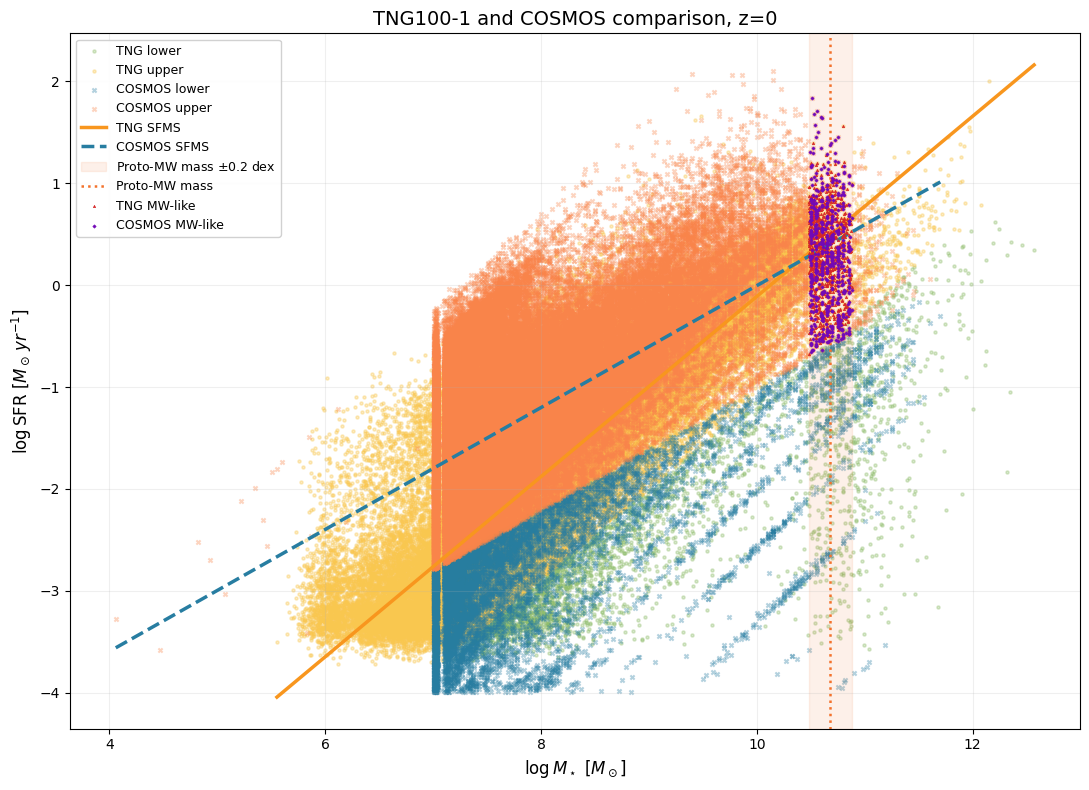

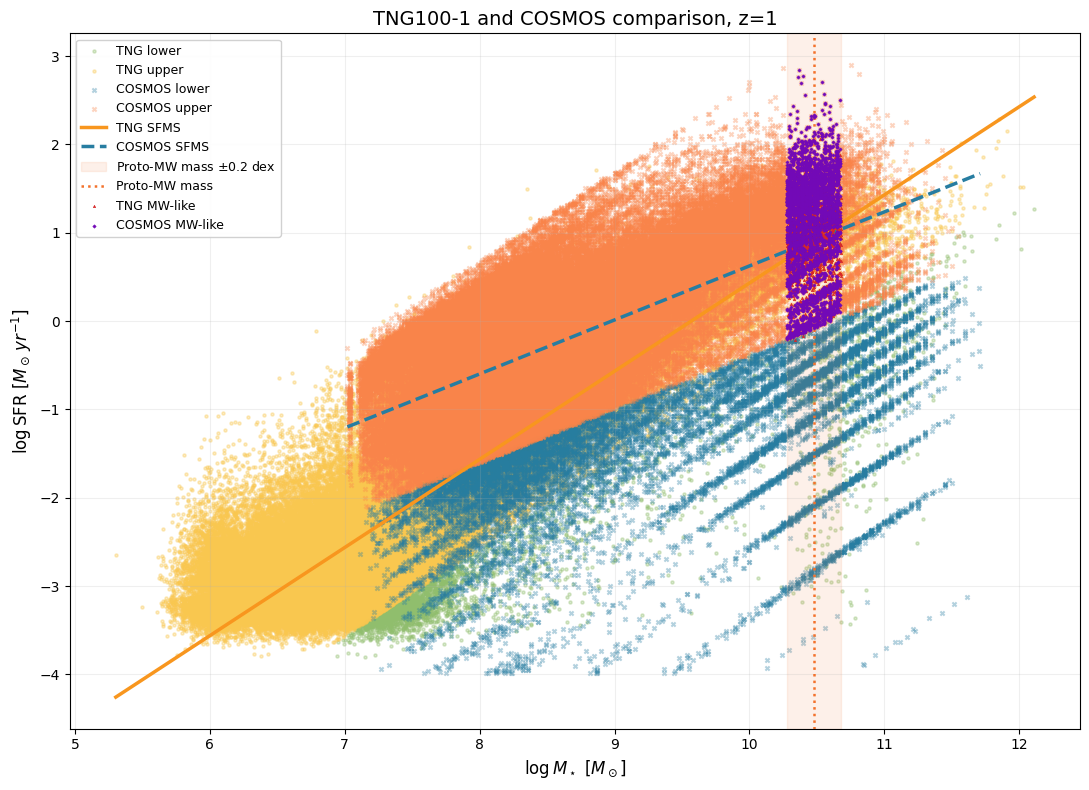

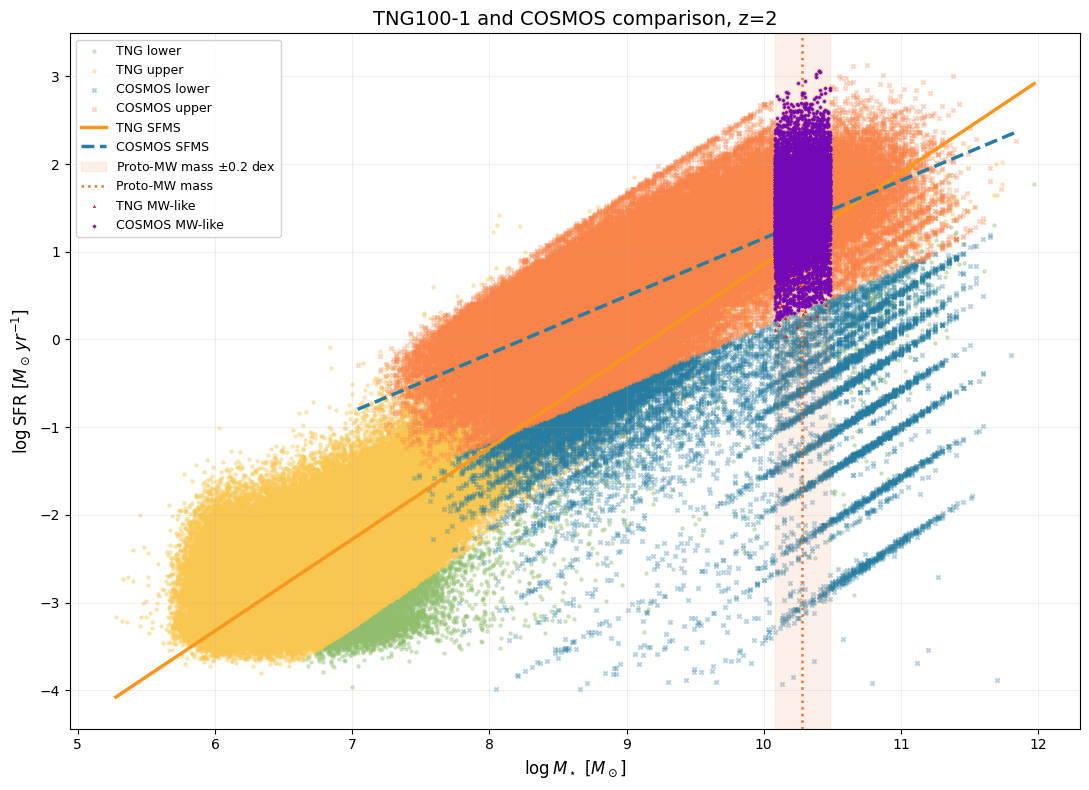

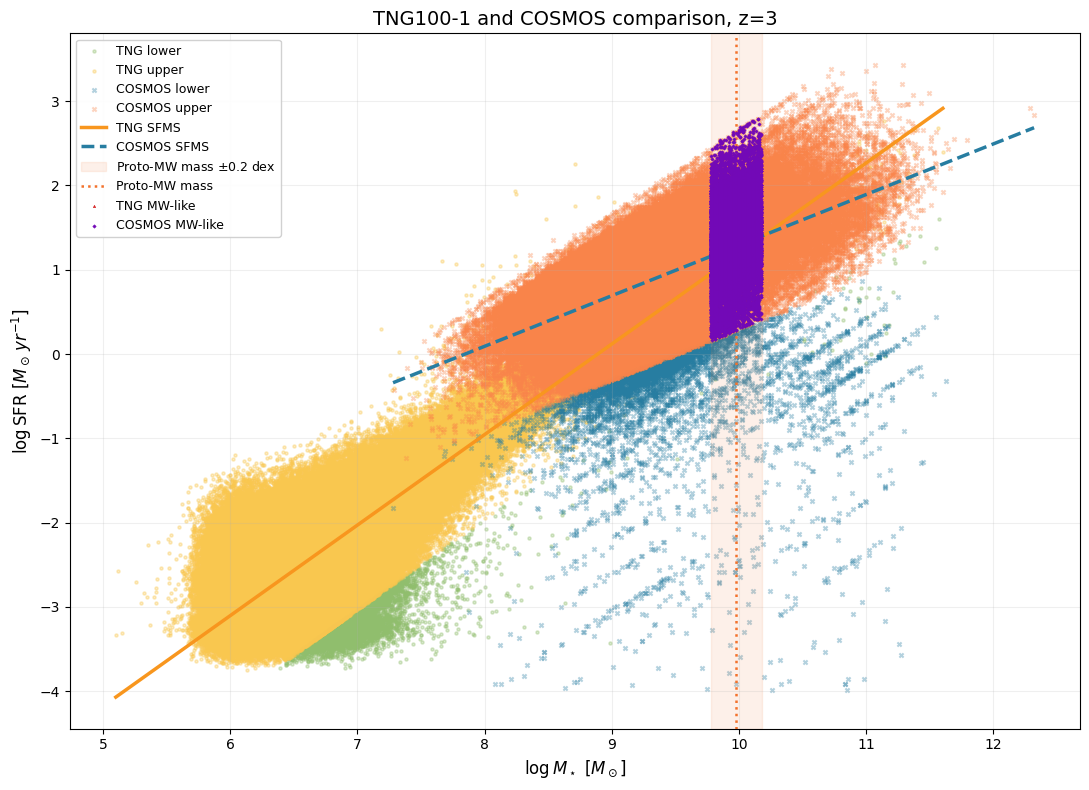

In [27]:
import numpy as np
import matplotlib.pyplot as plt

for z in snapshot_redshifts.values():

    # Provera da li postoje podaci za oba uzorka
    if z not in TNG_populations or z not in COSMOS_populations:
        print(f"Nedostaju podaci za z={z}")
        continue

    tng_upper = TNG_populations[z]["upper"]
    tng_lower = TNG_populations[z]["lower"]
    tng_mw = TNG_populations[z]["mw_mass_like"]
    tng_huber = TNG_populations[z]["huber"]
    tng_all = TNG_populations[z]["all"]


    cos_upper = COSMOS_populations[z]["upper"]
    cos_lower = COSMOS_populations[z]["lower"]
    cos_mw = COSMOS_populations[z]["mw_mass_like"]
    cos_huber = COSMOS_populations[z]["huber"]
    cos_all = COSMOS_populations[z]["all"]

    MW_mass = protoMWmass[z]


    plt.figure(figsize=(11, 8))


    plt.scatter(
        tng_lower["logM"],
        tng_lower["logSFR"],
        s=5,
        alpha=0.35,
        color="#90be6d",
        marker="o",
        label="TNG lower"
    )

    plt.scatter(
        tng_upper["logM"],
        tng_upper["logSFR"],
        s=5,
        alpha=0.35,
        color="#f9c74f",
        marker="o",
        label="TNG upper"
    )


    plt.scatter(
        cos_lower["logM"],
        cos_lower["logSFR"],
        s=9,
        alpha=0.35,
        color="#277da1",
        marker="x",
        label="COSMOS lower"
    )

    plt.scatter(
        cos_upper["logM"],
        cos_upper["logSFR"],
        s=9,
        alpha=0.35,
        color="#f9844a",
        marker="x",
        label="COSMOS upper"
    )


    x_tng = np.linspace(
        tng_all["logM"].min(),
        tng_all["logM"].max(),
        200
    )

    y_tng = tng_huber.predict(
        x_tng.reshape(-1, 1)
    )

    plt.plot(
        x_tng,
        y_tng,
        color="#f8961e",
        linewidth=2.5,
        linestyle="-",
        label="TNG SFMS"
    )


    x_cos = np.linspace(
        cos_all["logM"].min(),
        cos_all["logM"].max(),
        200
    )

    y_cos = cos_huber.predict(
        x_cos.reshape(-1, 1)
    )

    plt.plot(
        x_cos,
        y_cos,
        color="#277da1",
        linewidth=2.5,
        linestyle="--",
        label="COSMOS SFMS"
    )


    plt.axvspan(
        MW_mass - 0.2,
        MW_mass + 0.2,
        color="#f3722c",
        alpha=0.10,
        label=r"Proto-MW mass $\pm 0.2$ dex"
    )

    plt.axvline(
        MW_mass,
        color="#f3722c",
        linestyle=":",
        linewidth=1.8,
        label="Proto-MW mass"
    )


    plt.scatter(
        tng_mw["logM"],
        tng_mw["logSFR"],
        marker="^",
        s=3,
        color="#d62828",
        linewidths=0.4,
        label="TNG MW-like",
        zorder=5
    )


    plt.scatter(
        cos_mw["logM"],
        cos_mw["logSFR"],
        marker="D",
        s=3,
        color="#7209b7",
        linewidths=0.4,
        label="COSMOS MW-like",
        zorder=5
    )


    plt.xlabel(
        r"$\log M_\star\ [M_\odot]$",
        fontsize=12
    )

    plt.ylabel(
        r"$\log \mathrm{SFR}\ [M_\odot\,yr^{-1}]$",
        fontsize=12
    )

    plt.title(
        f"TNG100-1 and COSMOS comparison, z={z}",
        fontsize=14
    )

    plt.legend(
        fontsize=9,
        loc="best",
        framealpha=0.9
    )

    plt.grid(
        alpha=0.2
    )

    plt.tight_layout()
    plt.show()

# 3D SFR weighted 

['id', 'logM', 'logSFR', 'Z_weighted', 'delta_logSFR']
      id       logM    logSFR  Z_weighted  delta_logSFR
0     20  10.631641 -0.335965    0.013096     -0.783059
1     32  10.644636 -0.345226    0.045841     -0.803806
2     41  10.680394  0.889977    0.032064      0.399788
3  17211  10.682458  0.410602    0.033971     -0.081411
4  17216  10.585560  0.223236    0.060971     -0.183124

z = 0 | alpha = 1.0
Ukupan broj MW-like objekata = 836
Broj objekata u gornjih 10% = 84

Max-Np objekat
logM       = 10.8774
logSFR     = -0.0188
Z          = 5.040554e-02
Np         = 2.992482e+20

Gornjih 10% po Np
min(Np)    = 5.892476e+19
max(Np)    = 2.992482e+20
median(Np) = 8.583753e+19

Statistika svih objekata
min(Np)    = 9.226e+17
max(Np)    = 2.992e+20
median(Np) = 1.671e+19


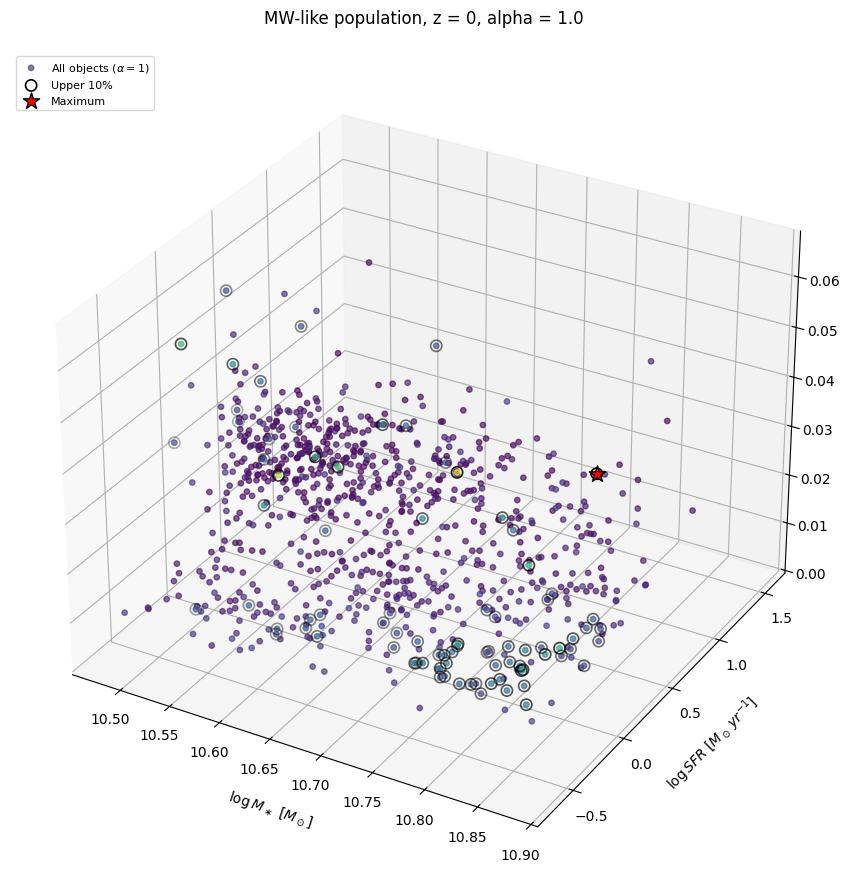


z = 0 | alpha = 0.0
Ukupan broj MW-like objekata = 836
Broj objekata u gornjih 10% = 84

Max-Np objekat
logM       = 10.8478
logSFR     = -0.3601
Z          = 9.809303e-03
Np         = 1.137113e+22

Gornjih 10% po Np
min(Np)    = 4.336471e+21
max(Np)    = 1.137113e+22
median(Np) = 5.926143e+21

Statistika svih objekata
min(Np)    = 4.512e+19
max(Np)    = 1.137e+22
median(Np) = 8.193e+20


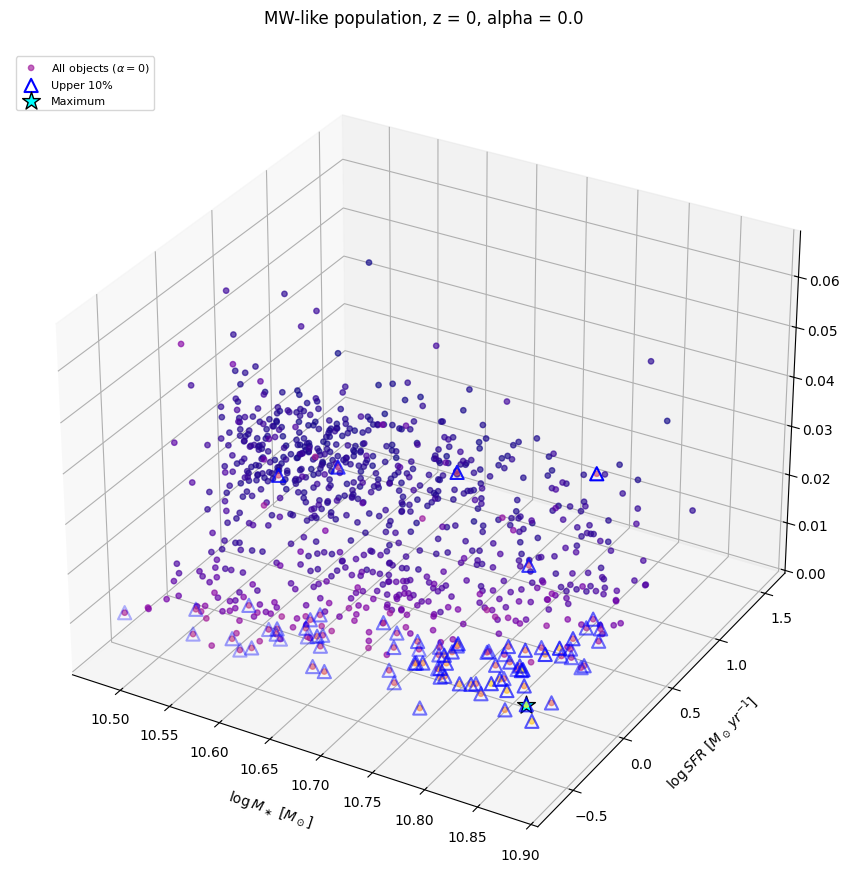

['id', 'logM', 'logSFR', 'Z_weighted', 'delta_logSFR']
   id       logM    logSFR  Z_weighted  delta_logSFR
0   9  10.587407  1.044491    0.027741      0.027843
1  10  10.664554  1.239006    0.027586      0.145363
2  13  10.669320  0.302072    0.013146     -0.796328
3  14  10.618810  1.407194    0.024700      0.359205
4  16  10.617486  1.159264    0.029178      0.112596

z = 1 | alpha = 1.0
Ukupan broj MW-like objekata = 1631
Broj objekata u gornjih 10% = 164

Max-Np objekat
logM       = 10.4993
logSFR     = -0.0398
Z          = 5.870873e-02
Np         = 6.413489e+19

Gornjih 10% po Np
min(Np)    = 6.911983e+18
max(Np)    = 6.413489e+19
median(Np) = 1.022152e+19

Statistika svih objekata
min(Np)    = 1.628e+17
max(Np)    = 6.413e+19
median(Np) = 2.263e+18


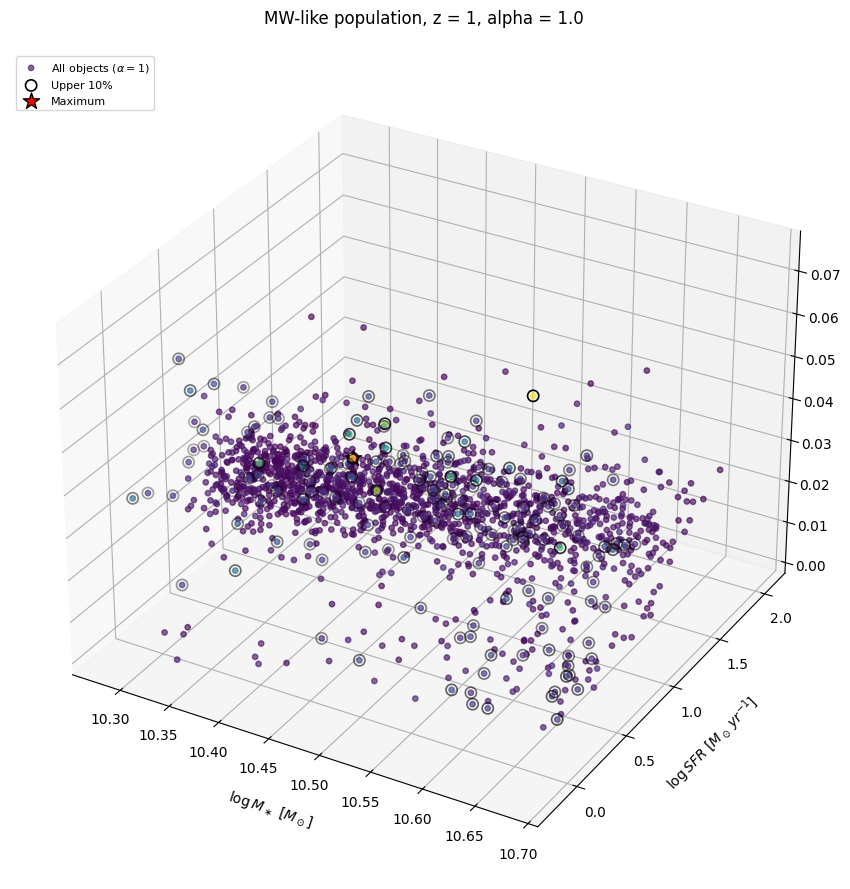


z = 1 | alpha = 0.0
Ukupan broj MW-like objekata = 1631
Broj objekata u gornjih 10% = 164

Max-Np objekat
logM       = 10.6748
logSFR     = 0.1567
Z          = 6.808630e-03
Np         = 1.559448e+21

Gornjih 10% po Np
min(Np)    = 2.790066e+20
max(Np)    = 1.559448e+21
median(Np) = 4.852555e+20

Statistika svih objekata
min(Np)    = 9.608e+18
max(Np)    = 1.559e+21
median(Np) = 9.749e+19


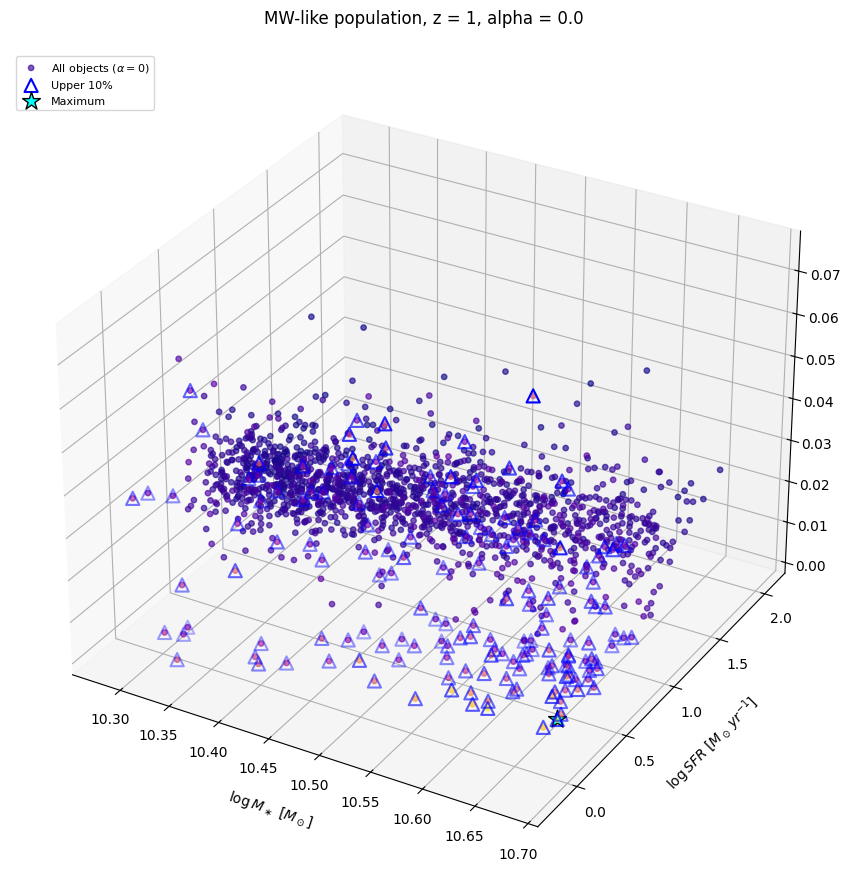

['id', 'logM', 'logSFR', 'Z_weighted', 'delta_logSFR']
   id       logM    logSFR  Z_weighted  delta_logSFR
0   6  10.213575  0.933943    0.035141     -0.146146
1   7  10.205244  1.323088    0.023927      0.251703
2   8  10.182852  0.776456    0.032868     -0.271534
3  13  10.106582  0.875870    0.022361     -0.092432
4  16  10.242908  0.144849    0.041629     -0.965887

z = 2 | alpha = 1.0
Ukupan broj MW-like objekata = 1459
Broj objekata u gornjih 10% = 146

Max-Np objekat
logM       = 10.3367
logSFR     = 0.2503
Z          = 6.699750e-02
Np         = 1.774707e+19

Gornjih 10% po Np
min(Np)    = 1.519162e+18
max(Np)    = 1.774707e+19
median(Np) = 2.148774e+18

Statistika svih objekata
min(Np)    = 3.479e+16
max(Np)    = 1.775e+19
median(Np) = 5.823e+17


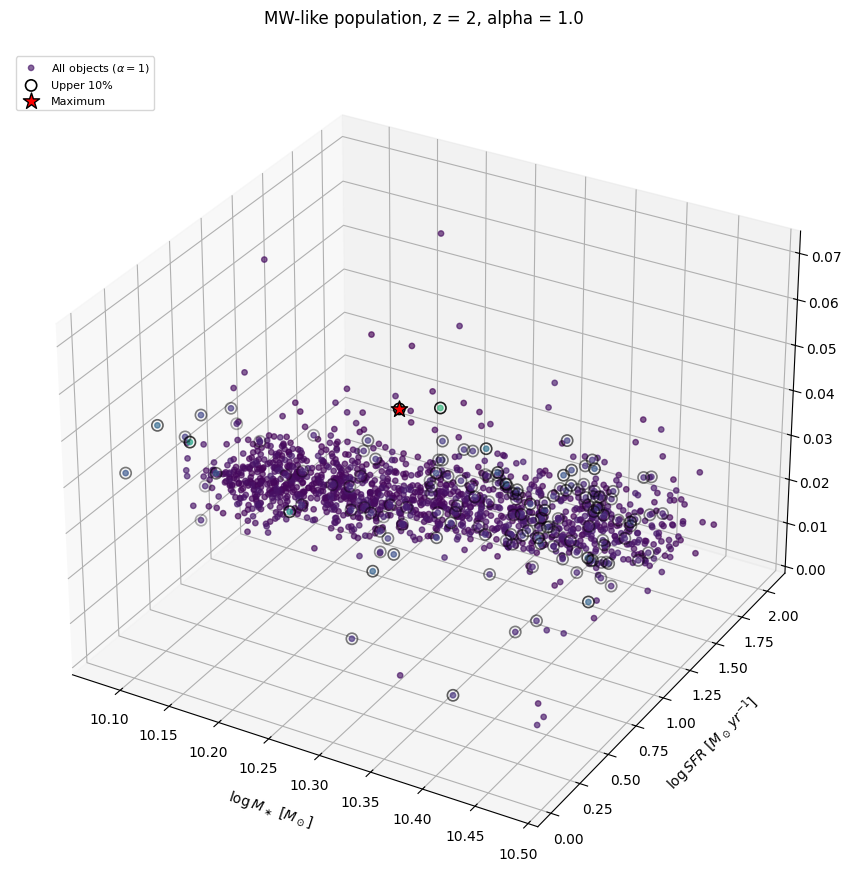


z = 2 | alpha = 0.0
Ukupan broj MW-like objekata = 1459
Broj objekata u gornjih 10% = 146

Max-Np objekat
logM       = 10.4531
logSFR     = 0.3882
Z          = 3.742082e-03
Np         = 3.296141e+20

Gornjih 10% po Np
min(Np)    = 5.374220e+19
max(Np)    = 3.296141e+20
median(Np) = 6.985260e+19

Statistika svih objekata
min(Np)    = 1.450e+18
max(Np)    = 3.296e+20
median(Np) = 2.563e+19


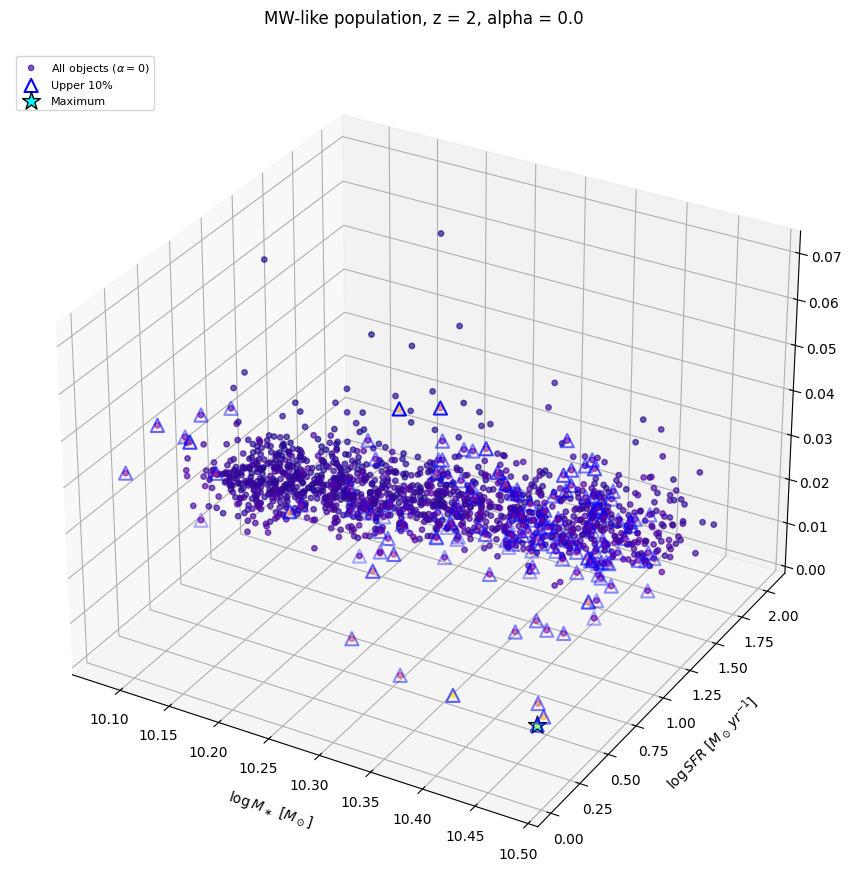

['id', 'logM', 'logSFR', 'Z_weighted', 'delta_logSFR']
    id       logM    logSFR  Z_weighted  delta_logSFR
0   15  10.003863  1.341132    0.018279      0.143650
1   16  10.087068  1.816583    0.019663      0.529721
2   17   9.792892  0.991021    0.018348      0.020172
3  845  10.130707  1.386197    0.015857      0.052456
4  853  10.013126  1.794954    0.021491      0.587522

z = 3 | alpha = 1.0
Ukupan broj MW-like objekata = 1112
Broj objekata u gornjih 10% = 112

Max-Np objekat
logM       = 10.1452
logSFR     = 0.6782
Z          = 4.208019e-02
Np         = 1.722960e+18

Gornjih 10% po Np
min(Np)    = 2.053624e+17
max(Np)    = 1.722960e+18
median(Np) = 2.709862e+17

Statistika svih objekata
min(Np)    = 7.730e+15
max(Np)    = 1.723e+18
median(Np) = 7.487e+16


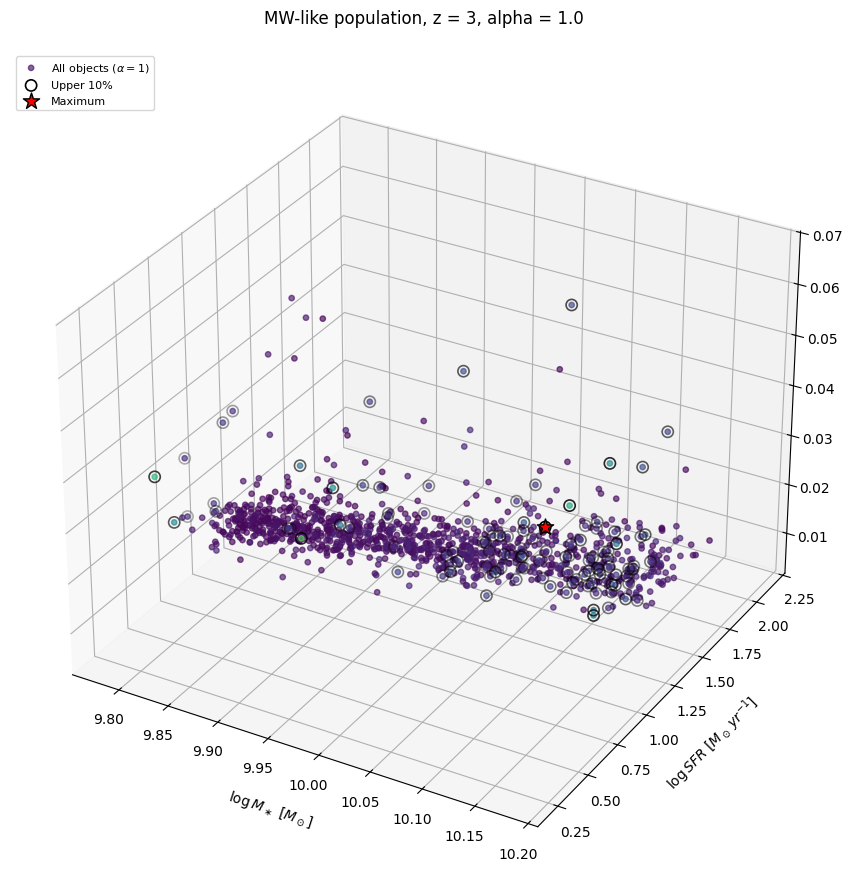


z = 3 | alpha = 0.0
Ukupan broj MW-like objekata = 1112
Broj objekata u gornjih 10% = 112

Max-Np objekat
logM       = 10.1452
logSFR     = 0.6782
Z          = 4.208019e-02
Np         = 4.094467e+19

Gornjih 10% po Np
min(Np)    = 9.612366e+18
max(Np)    = 4.094467e+19
median(Np) = 1.146398e+19

Statistika svih objekata
min(Np)    = 5.018e+17
max(Np)    = 4.094e+19
median(Np) = 4.854e+18


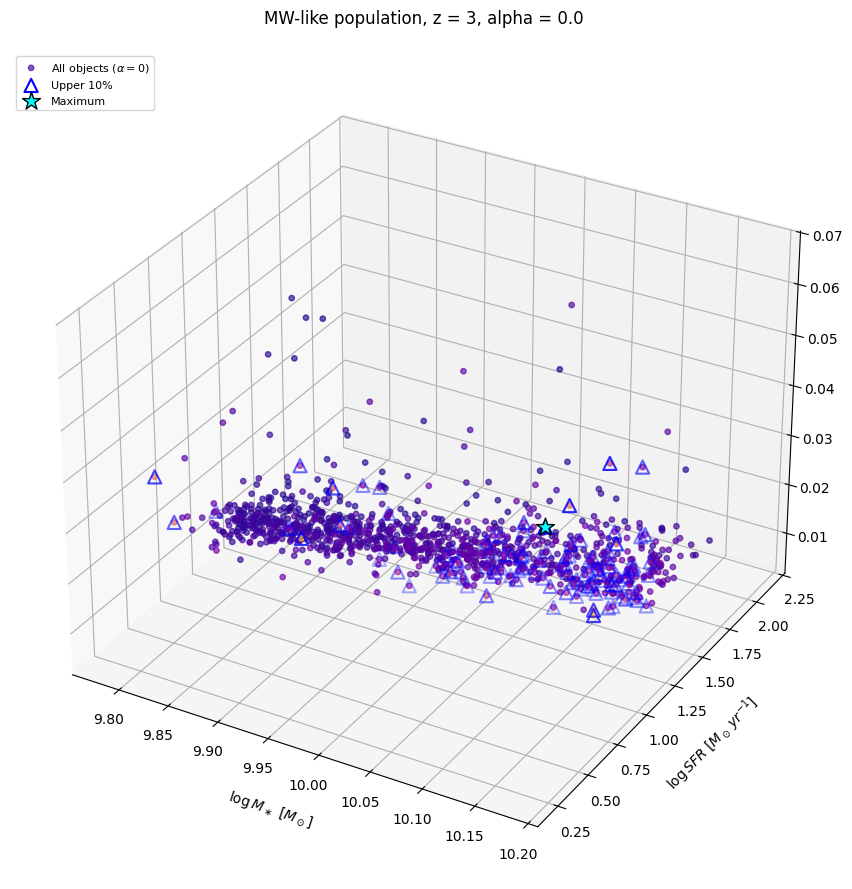

In [28]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

%matplotlib inline

param_alpha = [1.0, 0.0]

for z in range(4):

    df = pd.read_csv(f"MW_population_z{z}weighted.csv")
    
    print(df.columns.tolist())
    print(df.head())

    # Masa
    logM = df["logM"].values
    M = 10**logM

    # SFR
    logSFR = df["logSFR"].values
    SFR = 10**logSFR

    # Metalicnost
    Z = df["Z_weighted"].values

    N = len(df)
    for alpha in param_alpha:

        # Racunanje Np
        Np = M**2 * Z**alpha / SFR

        # Maksimalni Np objekat
        max_index = np.argmax(Np)

        max_Np = Np[max_index]
        max_logM = logM[max_index]
        max_logSFR = logSFR[max_index]
        max_Z = Z[max_index]

        # Gornjih 10% objekata po Np
        n_top10 = max(1, int(np.ceil(0.10 * N)))

        top10_indices = np.argsort(Np)[-n_top10:]

        top10_logM = logM[top10_indices]
        top10_logSFR = logSFR[top10_indices]
        top10_Z = Z[top10_indices]
        top10_Np = Np[top10_indices]

        # Statistika
        print()
        print("=" * 65)
        print(f"z = {z} | alpha = {alpha}")
        print("=" * 65)

        print(f"Ukupan broj MW-like objekata = {N}")
        print(f"Broj objekata u gornjih 10% = {n_top10}")

        print("\nMax-Np objekat")
        print(f"logM       = {max_logM:.4f}")
        print(f"logSFR     = {max_logSFR:.4f}")
        print(f"Z          = {max_Z:.6e}")
        print(f"Np         = {max_Np:.6e}")

        print("\nGornjih 10% po Np")
        print(f"min(Np)    = {top10_Np.min():.6e}")
        print(f"max(Np)    = {top10_Np.max():.6e}")
        print(f"median(Np) = {np.median(top10_Np):.6e}")

        print("\nStatistika svih objekata")
        print(f"min(Np)    = {Np.min():.3e}")
        print(f"max(Np)    = {Np.max():.3e}")
        print(f"median(Np) = {np.median(Np):.3e}")

        # Priprema novog grafika
        fig = plt.figure(figsize=(12, 9))
        ax = fig.add_subplot(111, projection="3d")

        # Grafik za alpha = 1
        if alpha == 1.0:

            ax.scatter(
                logM,
                logSFR,
                Z,
                c=Np,
                cmap="viridis",
                s=15,
                alpha=0.65,
                label=r"All objects ($\alpha=1$)"
            )

            ax.scatter(
                top10_logM,
                top10_logSFR,
                top10_Z,
                s=65,
                facecolors="none",
                edgecolors="black",
                linewidths=1.2,
                label=r"Upper 10%"
            )

            ax.scatter(
                [max_logM],
                [max_logSFR],
                [max_Z],
                s=150,
                marker="*",
                c="red",
                edgecolors="black",
                linewidths=1.0,
                label="Maximum"
            )

        # Grafik za alpha = 0
        else:

            ax.scatter(
                logM,
                logSFR,
                Z,
                c=Np,
                cmap="plasma",
                s=15,
                alpha=0.65,
                label=r"All objects ($\alpha=0$)"
            )

            ax.scatter(
                top10_logM,
                top10_logSFR,
                top10_Z,
                s=90,
                facecolors="none",
                edgecolors="blue",
                linewidths=1.5,
                marker="^",
                label=r"Upper 10%"
            )

            ax.scatter(
                [max_logM],
                [max_logSFR],
                [max_Z],
                s=180,
                marker="*",
                c="cyan",
                edgecolors="black",
                linewidths=1.0,
                label="Maximum"
            )

        ax.set_title(
            f"MW-like population, z = {z}, alpha = {alpha}",
            pad=20
        )

        ax.set_xlabel(r"$\log M_\ast\ [M_\odot]$", labelpad=10)
        ax.set_ylabel(r"$\log SFR\ [M_\odot\,yr^{-1}]$", labelpad=10)
        ax.set_zlabel("Z", labelpad=10)

        ax.legend(loc="upper left", fontsize=8)

        plt.tight_layout()
        plt.show()

# Np za sve TNG objekte


TNG POPULATION | z = 0 | alpha = 1.0
Ukupan broj objekata = 71575
Broj objekata u gornjih 10% = 7158

Max-Np objekat
Subhalo ID = 83280.0
logM       = 12.3210
logSFR     = -1.8355
Z          = 6.843263e-03
Np         = 2.055021e+24

Gornjih 10% po Np
min(Np)    = 1.634364e+18
max(Np)    = 2.055021e+24
median(Np) = 6.522111e+18

Statistika svih objekata
min(Np)    = 3.111e+05
max(Np)    = 2.055e+24
median(Np) = 6.332e+15


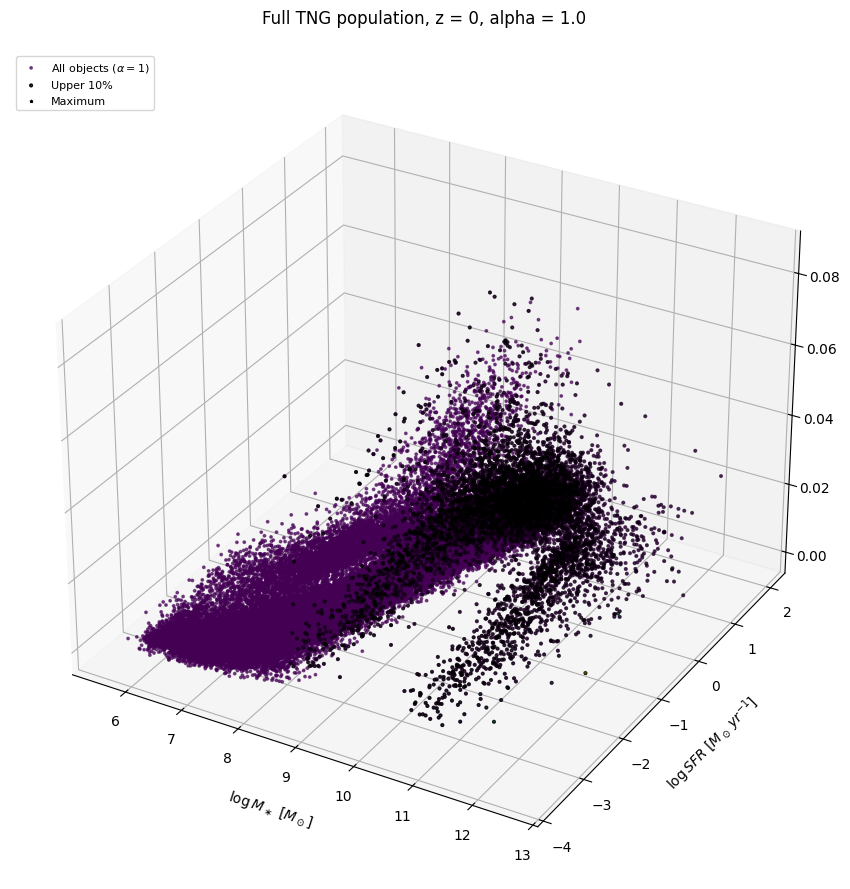


TNG POPULATION | z = 0 | alpha = 0.0
Ukupan broj objekata = 71575
Broj objekata u gornjih 10% = 7158

Max-Np objekat
Subhalo ID = 210764.0
logM       = 11.6796
logSFR     = -3.1565
Z          = 4.398244e-03
Np         = 3.278029e+26

Gornjih 10% po Np
min(Np)    = 7.645188e+19
max(Np)    = 3.278029e+26
median(Np) = 2.584703e+20

Statistika svih objekata
min(Np)    = 8.985e+12
max(Np)    = 3.278e+26
median(Np) = 1.193e+18


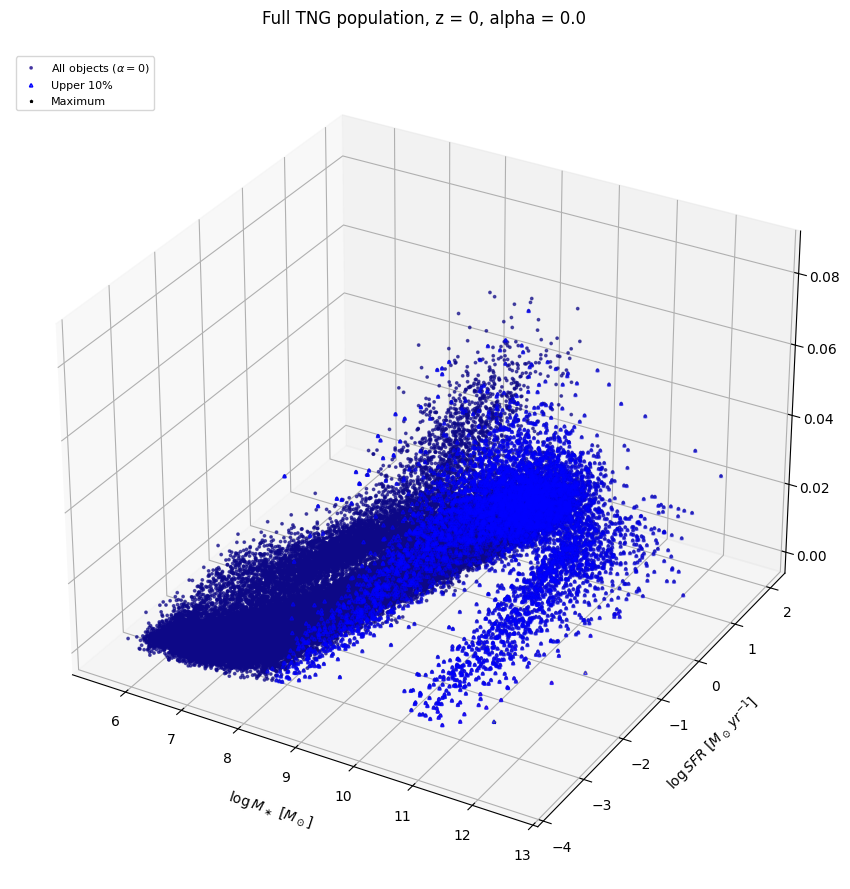


TNG POPULATION | z = 1 | alpha = 1.0
Ukupan broj objekata = 147241
Broj objekata u gornjih 10% = 14725

Max-Np objekat
Subhalo ID = 13761.0
logM       = 10.7814
logSFR     = -3.3666
Z          = 1.445495e-02
Np         = 1.228412e+23

Gornjih 10% po Np
min(Np)    = 5.629830e+16
max(Np)    = 1.228412e+23
median(Np) = 3.447916e+17

Statistika svih objekata
min(Np)    = 7.706e+05
max(Np)    = 1.228e+23
median(Np) = 5.089e+14


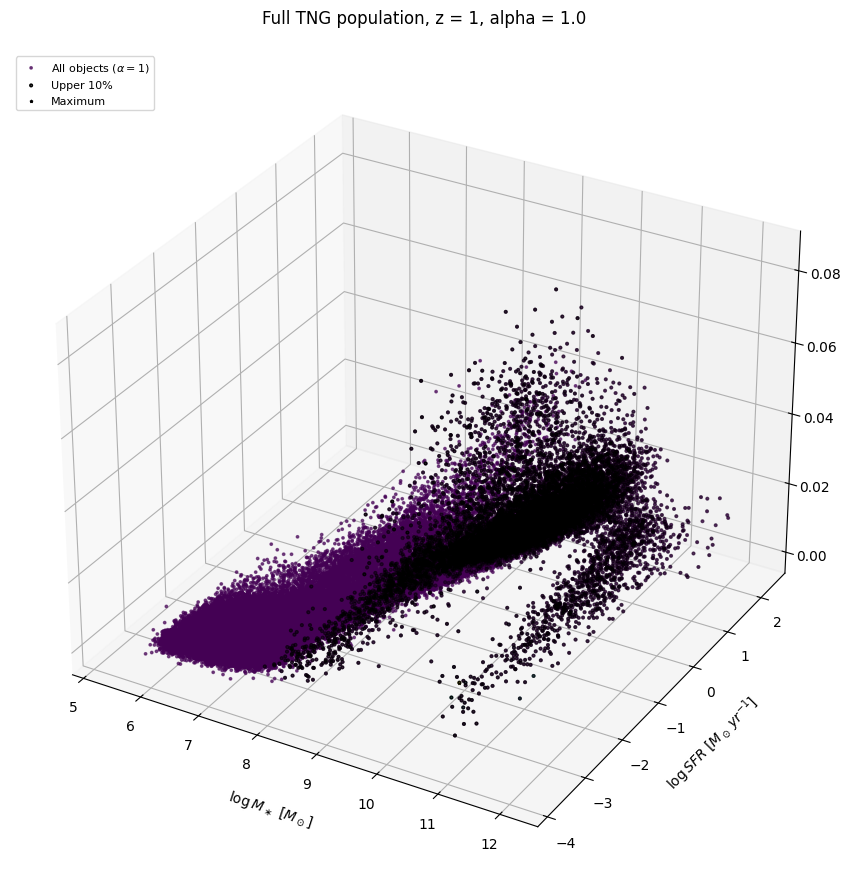


TNG POPULATION | z = 1 | alpha = 0.0
Ukupan broj objekata = 147241
Broj objekata u gornjih 10% = 14725

Max-Np objekat
Subhalo ID = 90819.0
logM       = 11.2391
logSFR     = -2.5159
Z          = 3.604610e-03
Np         = 9.864050e+24

Gornjih 10% po Np
min(Np)    = 4.658354e+18
max(Np)    = 9.864050e+24
median(Np) = 1.875371e+19

Statistika svih objekata
min(Np)    = 1.046e+13
max(Np)    = 9.864e+24
median(Np) = 1.820e+17


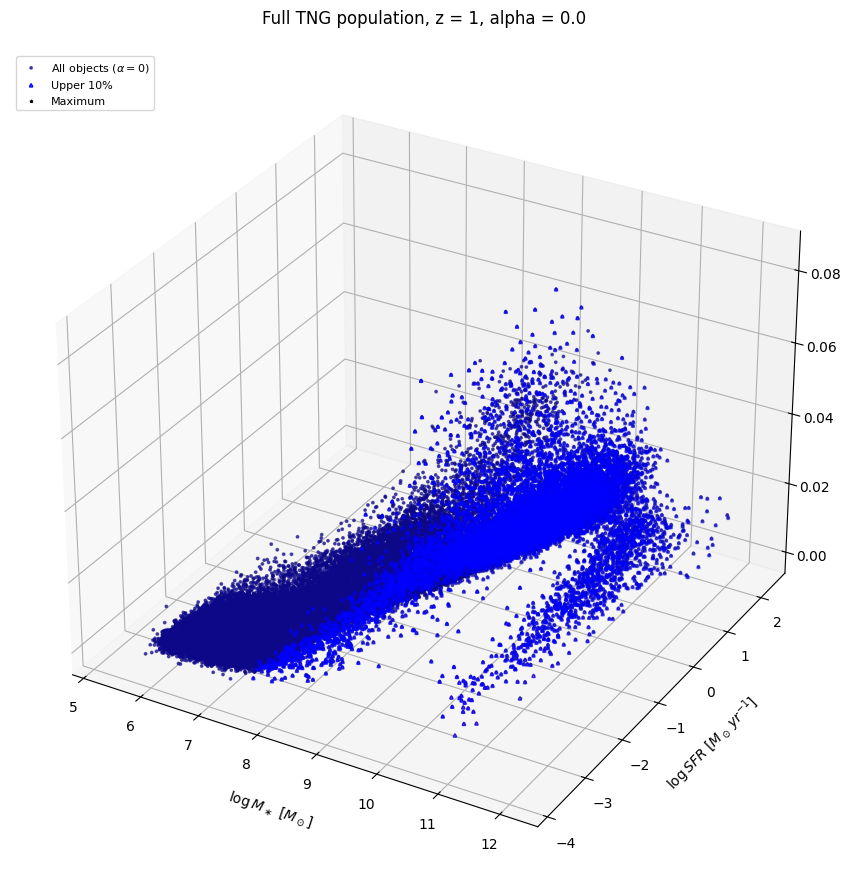


TNG POPULATION | z = 2 | alpha = 1.0
Ukupan broj objekata = 274398
Broj objekata u gornjih 10% = 27440

Max-Np objekat
Subhalo ID = 9924.0
logM       = 10.6566
logSFR     = -2.9111
Z          = 2.285908e-02
Np         = 3.832398e+22

Gornjih 10% po Np
min(Np)    = 2.510536e+15
max(Np)    = 3.832398e+22
median(Np) = 8.621064e+15

Statistika svih objekata
min(Np)    = 1.685e+05
max(Np)    = 3.832e+22
median(Np) = 4.743e+13


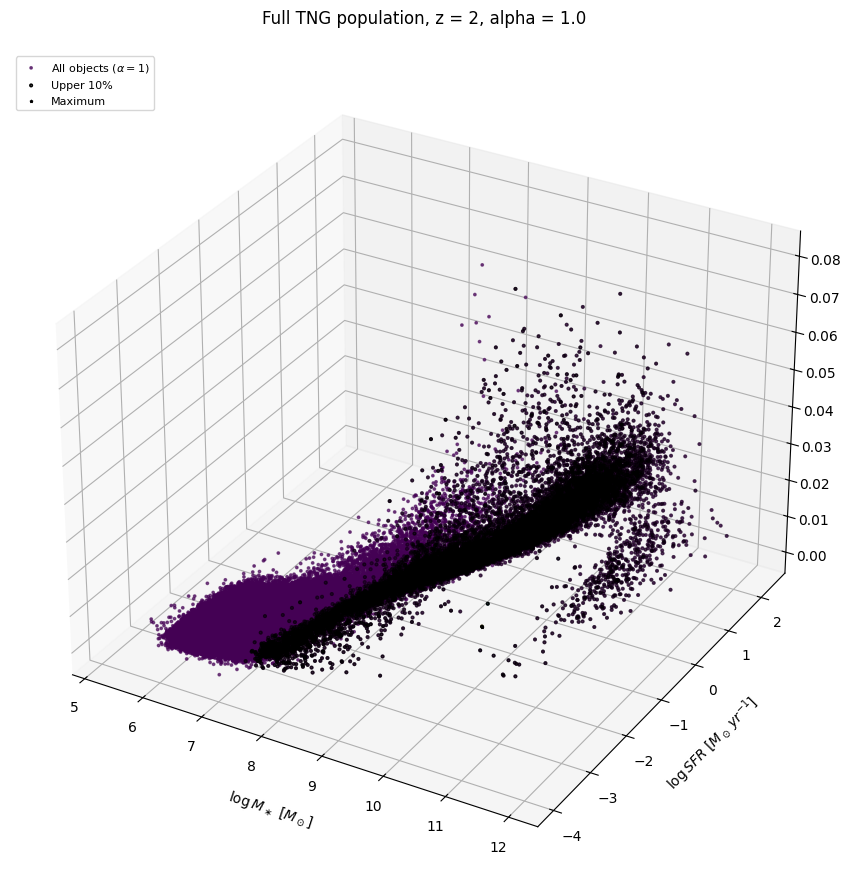


TNG POPULATION | z = 2 | alpha = 0.0
Ukupan broj objekata = 274398
Broj objekata u gornjih 10% = 27440

Max-Np objekat
Subhalo ID = 9924.0
logM       = 10.6566
logSFR     = -2.9111
Z          = 2.285908e-02
Np         = 1.676532e+24

Gornjih 10% po Np
min(Np)    = 4.680514e+17
max(Np)    = 1.676532e+24
median(Np) = 1.121584e+18

Statistika svih objekata
min(Np)    = 7.995e+12
max(Np)    = 1.677e+24
median(Np) = 3.084e+16


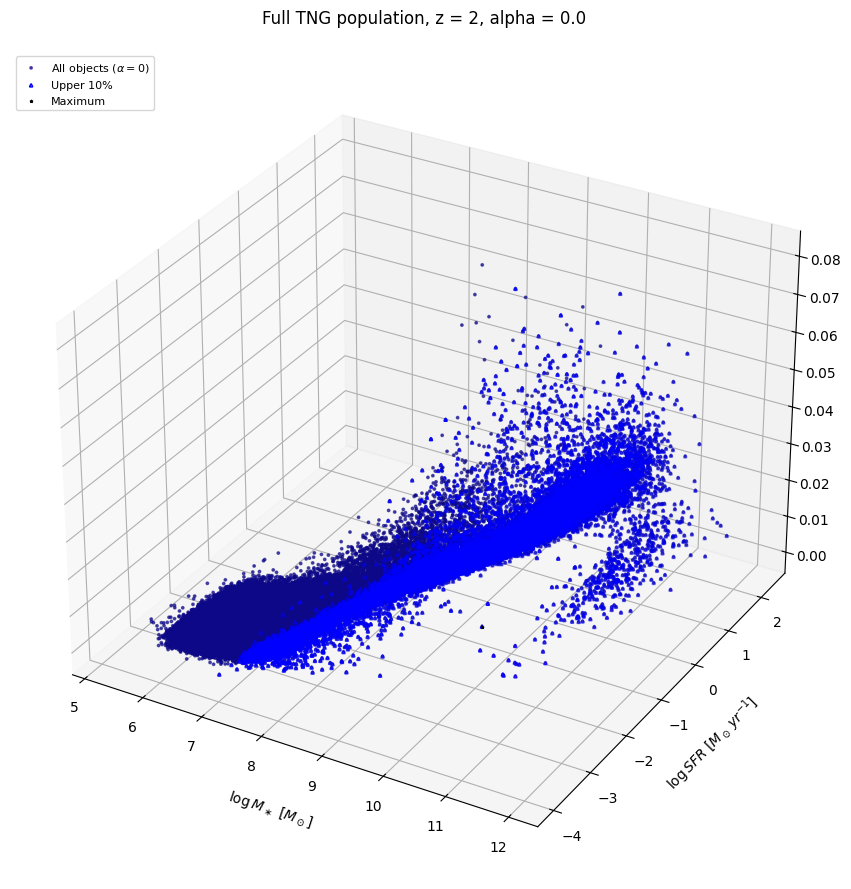


TNG POPULATION | z = 3 | alpha = 1.0
Ukupan broj objekata = 425208
Broj objekata u gornjih 10% = 42521

Max-Np objekat
Subhalo ID = 1452.0
logM       = 11.1491
logSFR     = -0.0186
Z          = 3.198935e-02
Np         = 6.634247e+20

Gornjih 10% po Np
min(Np)    = 2.872725e+14
max(Np)    = 6.634247e+20
median(Np) = 8.979308e+14

Statistika svih objekata
min(Np)    = 4.660e+04
max(Np)    = 6.634e+20
median(Np) = 8.593e+12


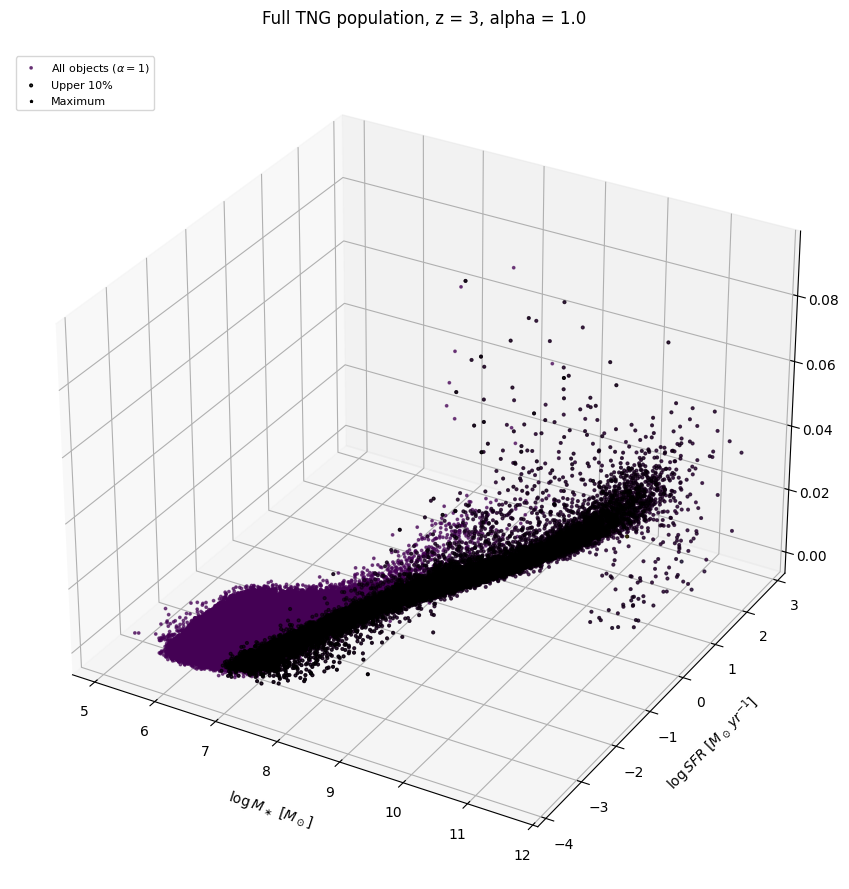


TNG POPULATION | z = 3 | alpha = 0.0
Ukupan broj objekata = 425208
Broj objekata u gornjih 10% = 42521

Max-Np objekat
Subhalo ID = 1452.0
logM       = 11.1491
logSFR     = -0.0186
Z          = 3.198935e-02
Np         = 2.073892e+22

Gornjih 10% po Np
min(Np)    = 8.980551e+16
max(Np)    = 2.073892e+22
median(Np) = 1.955881e+17

Statistika svih objekata
min(Np)    = 6.520e+12
max(Np)    = 2.074e+22
median(Np) = 8.165e+15


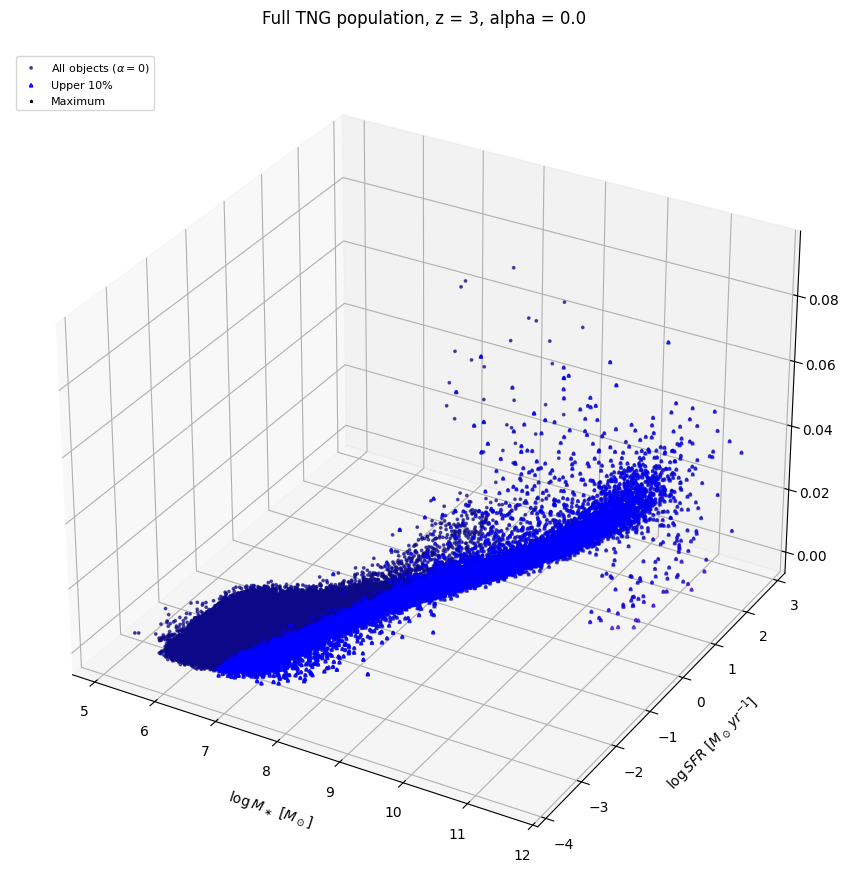

In [30]:
TNG_Np_results = {}

for snap, z in snapshot_redshifts.items():

    data = final_data[snap]

    stellar_mass = data["SubhaloMassType"][:, 4]
    mass_msun = stellar_mass * 1e10 / h

    sfr = data["SubhaloSFR"]

    Z = data["SubhaloGasMetallicitySfrWeighted"]

    logM = np.full(len(sfr), np.nan)
    logSFR = np.full(len(sfr), np.nan)

    valid_mass = np.isfinite(mass_msun) & (mass_msun > 0)
    valid_sfr = np.isfinite(sfr) & (sfr > 0)

    logM[valid_mass] = np.log10(mass_msun[valid_mass])
    logSFR[valid_sfr] = np.log10(sfr[valid_sfr])

    mask = (
        valid_mass &
        valid_sfr &
        (logSFR > -4) &
        np.isfinite(Z) &
        (Z > 0)
    )

    df = pd.DataFrame({
        "id": data["SubhaloID"][mask],
        "logM": logM[mask],
        "logSFR": logSFR[mask],
        "Z_weighted": Z[mask]
    }).reset_index(drop=True)

    logM = df["logM"].values
    logSFR = df["logSFR"].values

    M = 10**logM
    SFR = 10**logSFR
    Z = df["Z_weighted"].values

    N = len(df)

    TNG_Np_results[z] = {}

    for alpha in param_alpha:

        Np = M**2 * Z**alpha / SFR

        max_index = np.argmax(Np)

        max_object = df.iloc[max_index]

        max_Np = Np[max_index]

        n_top10 = max(1, int(np.ceil(0.10 * N)))

        top10_indices = np.argsort(Np)[-n_top10:]

        top10 = df.iloc[top10_indices].copy()
        top10["Np"] = Np[top10_indices]

        df_alpha = df.copy()
        df_alpha["Np"] = Np

        TNG_Np_results[z][alpha] = {
            "all": df_alpha,
            "top10": top10,
            "max_object": max_object,
            "max_Np": max_Np,
            "Np": Np
        }

        print()
        print("=" * 65)
        print(f"TNG POPULATION | z = {z} | alpha = {alpha}")
        print("=" * 65)

        print(f"Ukupan broj objekata = {N}")
        print(f"Broj objekata u gornjih 10% = {n_top10}")

        print("\nMax-Np objekat")
        print(f"Subhalo ID = {max_object['id']}")
        print(f"logM       = {max_object['logM']:.4f}")
        print(f"logSFR     = {max_object['logSFR']:.4f}")
        print(f"Z          = {max_object['Z_weighted']:.6e}")
        print(f"Np         = {max_Np:.6e}")

        print("\nGornjih 10% po Np")
        print(f"min(Np)    = {top10['Np'].min():.6e}")
        print(f"max(Np)    = {top10['Np'].max():.6e}")
        print(f"median(Np) = {top10['Np'].median():.6e}")

        print("\nStatistika svih objekata")
        print(f"min(Np)    = {Np.min():.3e}")
        print(f"max(Np)    = {Np.max():.3e}")
        print(f"median(Np) = {np.median(Np):.3e}")

        fig = plt.figure(figsize=(12, 9))
        ax = fig.add_subplot(111, projection="3d")

        if alpha == 1.0:

            scatter = ax.scatter(
                logM, logSFR, Z,
                c=Np,
                cmap="viridis",
                s=3,
                alpha=0.65,
                label=r"All objects ($\alpha=1$)"
            )

            ax.scatter(
                top10["logM"],
                top10["logSFR"],
                top10["Z_weighted"],
                s=3,
                facecolors="none",
                edgecolors="black",
                linewidths=1.2,
                label="Upper 10%"
            )

            ax.scatter(
                [max_object["logM"]],
                [max_object["logSFR"]],
                [max_object["Z_weighted"]],
                s=3,
                marker="*",
                c="red",
                edgecolors="black",
                linewidths=1.0,
                label="Maximum"
            )

        else:

            scatter = ax.scatter(
                logM, logSFR, Z,
                c=Np,
                cmap="plasma",
                s=3,
                alpha=0.65,
                label=r"All objects ($\alpha=0$)"
            )

            ax.scatter(
                top10["logM"],
                top10["logSFR"],
                top10["Z_weighted"],
                s=3,
                facecolors="none",
                edgecolors="blue",
                linewidths=1.5,
                marker="^",
                label="Upper 10%"
            )

            ax.scatter(
                [max_object["logM"]],
                [max_object["logSFR"]],
                [max_object["Z_weighted"]],
                s=3,
                marker="*",
                c="cyan",
                edgecolors="black",
                linewidths=1.0,
                label="Maximum"
            )

        ax.set_title(
            f"Full TNG population, z = {z}, alpha = {alpha}",
            pad=20
        )

        ax.set_xlabel(r"$\log M_\ast\ [M_\odot]$", labelpad=10)
        ax.set_ylabel(r"$\log SFR\ [M_\odot\,yr^{-1}]$", labelpad=10)
        ax.set_zlabel("Z", labelpad=10)

        ax.legend(loc="upper left", fontsize=8)

        plt.tight_layout()
        plt.show()